# Alquiler — 01 EDA

Exploración de los alquileres de Moscú para **predecir `monthly_rent_rub` a futuro**.

- **Objetivo:** predecir el alquiler mensual **futuro**. La idea rectora es un
  **split temporal** (entrenar con el pasado, evaluar con el futuro), que se aplicará
  en los notebooks siguientes. Este EDA ya se ordena en esa lógica: join temprano,
  mirada temporal y cuidado con usar información que no estaría disponible al predecir.
- **Variable objetivo:** `monthly_rent_rub` se trabaja **siempre en
  rublos originales**.
- **Orden:** carga + **joins primero** (`district_prices_monthly.csv` y
  `metro_stations.csv`), y todo el análisis posterior sobre la base enriquecida.
- **Outliers:** solo **diagnóstico temprano completo** en este notebook. La
  aplicación efectiva de la estrategia elegida queda para `02_Limpieza`.


## 0. Entorno

Correr con el kernel **(.venv)**. Si falta el entorno:

```
source .venv/bin/activate
pip install -r requirements.txt
```


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

DATA_DIR = Path("..") / "data"
TARGET = "monthly_rent_rub"
RNG = np.random.default_rng(42)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")


def vif_tabla(df_, cols):
    """VIF de un bloque numerico (sin la objetivo). VIF>5 vigilar, >10 colinealidad seria."""
    x = df_[cols].dropna().astype(float)
    x = sm.add_constant(x, has_constant="add")
    filas = []
    for i, col in enumerate(x.columns):
        if col == "const":
            continue
        filas.append({"variable": col,
                      "VIF": round(float(variance_inflation_factor(x.values, i)), 2)})
    return pd.DataFrame(filas).sort_values("VIF", ascending=False)


def eta2(df_, cat, y=TARGET):
    """Eta2: fraccion de la varianza de y explicada por las medias de cada grupo."""
    g = df_.groupby(cat, observed=True)[y]
    media = df_[y].mean()
    ss_entre = float((g.size() * (g.mean() - media) ** 2).sum())
    ss_total = float(((df_[y] - media) ** 2).sum())
    return ss_entre / ss_total if ss_total else np.nan


def reg_simple(df_, x, y=TARGET):
    """Regresion lineal simple y = a + b*x sobre la objetivo cruda."""
    d = df_[[x, y]].dropna()
    modelo = sm.OLS(d[y], sm.add_constant(d[x].astype(float))).fit()
    return {"variable": x, "pendiente": round(float(modelo.params[x]), 4),
            "r": round(float(d[x].corr(d[y])), 3),
            "R2": round(float(modelo.rsquared), 4),
            "p": f"{float(modelo.pvalues[x]):.2e}", "n": len(d)}


def scatter_reg(ax, df_, x, y=TARGET, muestra=4000, color="steelblue"):
    """Scatter + recta lineal simple, con r y R2 de esa misma recta."""
    d = df_.sample(min(muestra, len(df_)), random_state=42)
    sns.regplot(data=d, x=x, y=y, ax=ax, scatter_kws={"alpha": 0.35, "s": 12},
                line_kws={"color": "crimson", "lw": 1.6}, ci=None, color=color)
    r = reg_simple(df_, x, y)
    ax.set_title(f"{x} vs {y}\nr={r['r']}, R2={r['R2']}, pendiente={r['pendiente']}")
    ax.set_ylabel(y)


print("pandas", pd.__version__, "| numpy", np.__version__)
print("DATA_DIR:", DATA_DIR.resolve(), "| existe:", DATA_DIR.exists())

pandas 3.0.6 | numpy 2.5.4
DATA_DIR: /Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals/data | existe: True


## 1. Carga y joins

Se carga `rentals.csv` y **enseguida** se enriquece, para que todo lo que sigue
ya vea el contexto distrital-mensual y de metro:

- `rentals` LEFT JOIN `district_prices_monthly` por (`district`, `year_month`),
  donde `year_month` se deriva de `date_posted`.
- `rentals` LEFT JOIN `metro_stations` por estación (`metro_station` = `station_name`).

Choques de nombres: la línea y la distancia al centro de la **estación** se renombran
(`station_line`, `station_to_center_km`, `station_lat`, `station_lon`) para no pisar
`metro_line` ni el `to_center_km` del **aviso**, que son los que mandan.


In [2]:
rentals = pd.read_csv(DATA_DIR / "rentals.csv", parse_dates=["date_posted"])
monthly = pd.read_csv(DATA_DIR / "district_prices_monthly.csv")
metro = pd.read_csv(DATA_DIR / "metro_stations.csv")

rentals["year_month"] = rentals["date_posted"].dt.strftime("%Y-%m")
print(f"rentals: {len(rentals):,} filas x {rentals.shape[1]} columnas | "
      f"{rentals['date_posted'].min().date()} -> {rentals['date_posted'].max().date()}")
print(f"monthly: {monthly.shape} | {monthly['year_month'].min()} -> {monthly['year_month'].max()}")
print(f"metro:   {metro.shape} | estaciones unicas: {metro['station_name'].nunique()}")

n0 = len(rentals)
df = rentals.merge(monthly, on=["district", "year_month"], how="left",
                   suffixes=("", "_dup"), indicator="m_distrito_mes")
print(f"join distrito-mes: {n0:,} -> {len(df):,} filas | "
      f"match={(df['m_distrito_mes'] == 'both').mean():.2%} | "
      f"claves duplicadas en monthly: {int(monthly.duplicated(['district', 'year_month']).sum())}")
df = df.drop(columns=["m_distrito_mes"])
if "okrug_dup" in df.columns:
    print(f"okrug del aviso == okrug del mensual: "
          f"{(df['okrug'] == df['okrug_dup']).mean():.2%} (se conserva el del aviso)")
    df = df.drop(columns=["okrug_dup"])

metro_r = metro.rename(columns={"station_name": "metro_station", "line": "station_line",
                                "lat": "station_lat", "lon": "station_lon",
                                "to_center_km": "station_to_center_km"})
df = df.merge(metro_r, on="metro_station", how="left", indicator="m_metro")
print(f"join metro: match={(df['m_metro'] == 'both').mean():.2%} | "
      f"linea del aviso == linea de la estacion: "
      f"{(df['metro_line'] == df['station_line']).mean():.2%}")
df = df.drop(columns=["m_metro"])
df["year_month_dt"] = pd.to_datetime(df["year_month"])
df["estacion_antiguedad"] = df["date_posted"].dt.year - df["year_opened"]
print(f"base enriquecida: {df.shape[0]:,} filas x {df.shape[1]} columnas "
      f"(sin perder filas: {len(df) == n0})")
display(df.head())

rentals: 20,000 filas x 23 columnas | 2021-01-01 -> 2026-04-29
monthly: (9804, 13) | 2020-01 -> 2026-04
metro:   (104, 6) | estaciones unicas: 104
join distrito-mes: 20,000 -> 20,000 filas | match=100.00% | claves duplicadas en monthly: 0
okrug del aviso == okrug del mensual: 100.00% (se conserva el del aviso)
join metro: match=100.00% | linea del aviso == linea de la estacion: 100.00%
base enriquecida: 20,000 filas x 40 columnas (sin perder filas: True)


,id,date_posted,district,okrug,lat,lon,total_area,rooms,floor,total_floors,building_year,building_type,renovation,furnished,pets_allowed,deposit_months,metro_station,metro_line,metro_distance_min,to_center_km,monthly_rent_rub,rent_per_sqm,year_month,secondary_price_per_sqm,newbuild_price_per_sqm,rental_price_per_sqm_monthly,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,n_listings_rental,cbr_key_rate_pct,avg_mortgage_rate_pct,station_line,station_lat,station_lon,year_opened,station_to_center_km,year_month_dt,estacion_antiguedad
0,R000001,2025-01-16,Nagatinsky Zaton,YuAO,55.70058,37.69344,34.7,1,5,9,1958,brick,cosmetic,False,True,1,Ugreshskaya,MCC,28,7.47,26200,756,2025-01,318400,364200,1327,-4.69,1.67,133,25,108,21.0,23.5,MCC,55.7036,37.6892,2016,7.04,2025-01-01,9
1,R000002,2022-11-12,Chertanovo Severnoye,YuAO,55.64717,37.61690,53.4,1,10,12,2010,monolith,cosmetic,True,False,1,Kuznetsky Most,Tagansko-Krasnopresnenskaya,152,11.87,37200,696,2022-11,256400,282600,1068,0.12,3.32,172,79,46,7.5,10.0,Tagansko-Krasnopresnenskaya,55.7619,37.6253,1975,0.93,2022-11-01,47
2,R000003,2026-03-06,Savyolovsky,SAO,55.78584,37.57104,69.9,2,15,22,2009,monolith,euro,True,False,1,Rizhskaya,Kaluzhsko-Rizhskaya,43,4.72,96700,1384,2026-03,381100,413000,1588,5.70,3.20,55,26,88,17.0,19.5,Kaluzhsko-Rizhskaya,55.7919,37.6362,1958,4.33,2026-03-01,68
3,R000004,2024-10-11,Beskudnikovsky,SAO,55.87034,37.56080,44.6,2,14,17,1980,brick,no_renovation,True,False,1,Trubnaya,Lyublinsko-Dmitrovskaya,145,13.48,30200,677,2024-10,277100,295500,1155,-4.49,-8.59,72,34,90,21.0,23.5,Lyublinsko-Dmitrovskaya,55.7702,37.6209,2007,1.81,2024-10-01,17
4,R000005,2023-07-11,Shchapovskoye,TAO,55.37723,37.51217,56.7,1,3,5,1979,panel,euro,False,False,1,Dubrovka,Lyublinsko-Dmitrovskaya,472,42.44,18700,330,2023-07,118100,122100,492,1.13,-4.50,151,30,84,13.0,15.5,Lyublinsko-Dmitrovskaya,55.7176,37.6779,1999,5.39,2023-07-01,24


In [3]:
DIC = [
    ("id", "identificador", "ID unico del aviso"),
    ("date_posted", "fecha de publicacion", "Fecha de publicacion del aviso (YYYY-MM-DD)"),
    ("year_month / year_month_dt", "mes de publicacion", "Derivada de date_posted; clave del join mensual y eje temporal"),
    ("district", "distrito", "Distrito de Moscu (129 valores)"),
    ("okrug", "okrug", "Agrupacion de distritos (11 valores: CAO, ZAO, ...)"),
    ("lat / lon", "latitud / longitud", "Coordenadas del inmueble"),
    ("total_area", "superficie total (m2)", "Superficie total en metros cuadrados"),
    ("rooms", "ambientes", "Cantidad de ambientes (1 a 4)"),
    ("floor / total_floors", "piso / pisos del edificio", "Piso del depto. y pisos totales del edificio"),
    ("building_year", "anio de construccion", "Anio de construccion del edificio"),
    ("building_type", "tipo de edificio", "brick, panel, monolith, stalin, khrushchev, modern_panel"),
    ("renovation", "renovacion", "no_renovation, cosmetic, euro, designer"),
    ("furnished / pets_allowed", "amueblado / mascotas", "True/False del aviso"),
    ("deposit_months", "meses de deposito", "Meses de alquiler pedidos como deposito"),
    ("metro_station / metro_line", "estacion / linea de metro", "Estacion mas cercana y su linea (segun el aviso)"),
    ("metro_distance_min", "distancia al metro (min)", "Minutos hasta la estacion mas cercana"),
    ("to_center_km", "distancia al centro (km)", "Distancia del inmueble al centro"),
    ("monthly_rent_rub", "alquiler mensual (RUB) — OBJETIVO", "Se usa siempre cruda, sin normalizar ni transformar"),
    ("rent_per_sqm", "alquiler por m2 (RUB/m2)", "Deriva de la objetivo (objetivo / total_area): fuga si se usa como predictora"),
    ("rental_price_per_sqm_monthly", "alquiler distrital del mes (RUB/m2)", "Contexto distrito-mes (join monthly)"),
    ("secondary_price_per_sqm / newbuild_price_per_sqm", "venta distrital del mes (RUB/m2)", "Contexto de venta del distrito-mes (join monthly)"),
    ("secondary_mom_change_pct / newbuild_mom_change_pct", "variacion mensual de venta (%)", "Contexto distrito-mes (join monthly)"),
    ("n_listings_secondary / n_listings_newbuild / n_listings_rental", "avisos del distrito-mes", "Volumen de mercado del distrito-mes (join monthly)"),
    ("cbr_key_rate_pct / avg_mortgage_rate_pct", "tasas macro (%)", "Tasa clave e hipotecaria del mes (join monthly)"),
    ("station_line / station_lat / station_lon / year_opened / station_to_center_km", "datos de la estacion", "Linea, coordenadas, anio de apertura y distancia al centro de la estacion (join metro)"),
    ("estacion_antiguedad", "antiguedad de la estacion (anios)", "Derivada: anio de publicacion - year_opened"),
]
display(pd.DataFrame(DIC, columns=["columna", "nombre", "descripcion"]))

,columna,nombre,descripcion
0,id,identificador,ID unico del aviso
1,date_posted,fecha de publicacion,Fecha de publicacion del aviso (YYYY-MM-DD)
2,year_month / year_month_dt,mes de publicacion,Derivada de date_posted; clave del join mensua...
3,district,distrito,Distrito de Moscu (129 valores)
4,okrug,okrug,"Agrupacion de distritos (11 valores: CAO, ZAO,..."
5,lat / lon,latitud / longitud,Coordenadas del inmueble
6,total_area,superficie total (m2),Superficie total en metros cuadrados
7,rooms,ambientes,Cantidad de ambientes (1 a 4)
8,floor / total_floors,piso / pisos del edificio,Piso del depto. y pisos totales del edificio
9,building_year,anio de construccion,Anio de construccion del edificio


### 1.1 Estructura, nulos y duplicados (base ya enriquecida)

In [4]:
rows = []
for col in df.columns:
    s = df[col]
    rows.append({"columna": col, "dtype": str(s.dtype),
                 "n_nulos": int(s.isna().sum()),
                 "pct_nulos": round(100 * s.isna().mean(), 2),
                 "n_unicos": int(s.nunique())})
display(pd.DataFrame(rows))
print("filas duplicadas completas:", int(df.duplicated().sum()))
print("ids duplicados:", int(df["id"].duplicated().sum()))

,columna,dtype,n_nulos,pct_nulos,n_unicos
0,id,str,0,0.0,20000
1,date_posted,datetime64[us],0,0.0,1945
2,district,str,0,0.0,129
3,okrug,str,0,0.0,11
4,lat,float64,0,0.0,15985
5,lon,float64,0,0.0,16678
6,total_area,float64,0,0.0,695
7,rooms,int64,0,0.0,4
8,floor,int64,0,0.0,22
9,total_floors,int64,0,0.0,5


filas duplicadas completas: 0
ids duplicados: 0


In [5]:
miss = df.isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]
if miss.empty:
    print("Sin valores nulos en la base enriquecida")
else:
    fig, ax = plt.subplots(figsize=(7, max(2, 0.4 * len(miss))))
    miss.sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_xlabel("% nulos")
    ax.set_title("Nulos por columna (base enriquecida)")
    plt.tight_layout()
    plt.show()

Sin valores nulos en la base enriquecida


## 2. Univariado numérico: centro, dispersión y sesgo

La objetivo se describe **cruda**. Que sea asimétrica es un dato del problema
(precios), no algo a corregir en esta etapa.


In [6]:
num = df.select_dtypes(include=np.number)
desc = num.describe().T
desc["skew"] = num.skew().round(3)
desc["kurtosis"] = num.kurtosis().round(3)


def tag_skew(v):
    a = abs(v)
    if a <= 0.5:
        return "simetrico"
    if a <= 1.0:
        return "sesgo moderado"
    return "muy sesgado"


desc["lectura_skew"] = desc["skew"].map(tag_skew)
display(desc.round(3))
print("Regla: |skew|<=0.5 simetrico; 0.5-1 moderado; >1 muy sesgado.")
print(f"{TARGET}: media={df[TARGET].mean():,.0f} | mediana={df[TARGET].median():,.0f} "
      f"| skew={float(df[TARGET].skew()):.2f} (media > mediana: cola derecha)")

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,lectura_skew
lat,20000.0,55.713,0.144,55.230,55.636,55.740,55.818,56.013,-0.980,0.908,sesgo moderado
lon,20000.0,37.542,0.181,36.702,37.465,37.564,37.652,37.908,-1.224,2.969,muy sesgado
total_area,20000.0,55.387,12.740,22.100,45.700,53.800,63.300,104.600,0.577,-0.087,sesgo moderado
rooms,20000.0,1.794,0.865,1.000,1.000,2.000,2.000,4.000,0.847,-0.115,sesgo moderado
floor,20000.0,6.608,4.830,1.000,3.000,5.000,9.000,22.000,1.074,0.619,muy sesgado
total_floors,20000.0,12.191,5.692,5.000,9.000,9.000,17.000,22.000,0.437,-1.034,simetrico
building_year,20000.0,1987.823,22.500,1935.000,1968.000,1988.000,2008.000,2024.000,-0.101,-1.141,simetrico
deposit_months,20000.0,1.101,0.541,0.000,1.000,1.000,1.000,2.000,0.072,0.275,simetrico
metro_distance_min,20000.0,152.385,167.803,0.000,33.000,103.000,198.000,966.000,1.963,4.039,muy sesgado
to_center_km,20000.0,16.360,12.801,0.020,9.040,13.230,18.030,71.060,2.121,4.828,muy sesgado


Regla: |skew|<=0.5 simetrico; 0.5-1 moderado; >1 muy sesgado.
monthly_rent_rub: media=52,433 | mediana=45,800 | skew=1.82 (media > mediana: cola derecha)


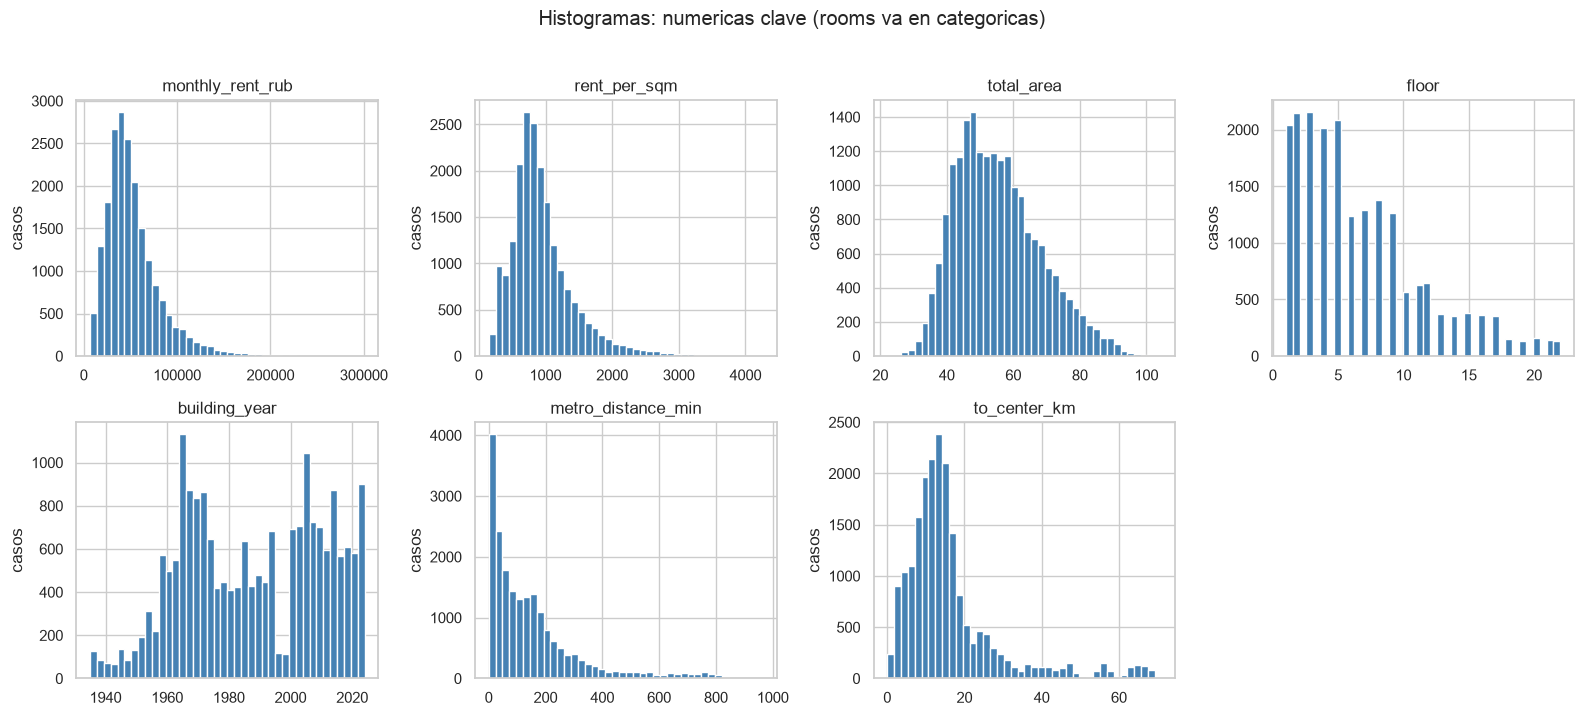

In [7]:
# rooms (4 valores) no va aca: va como barras de conteo en la seccion categorica
KEY_NUM = [TARGET, "rent_per_sqm", "total_area", "floor",
           "building_year", "metro_distance_min", "to_center_km"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), KEY_NUM):
    df[col].hist(bins=40, ax=ax, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("casos")
for ax in axes.ravel()[len(KEY_NUM):]:
    ax.axis("off")
plt.suptitle("Histogramas: numericas clave (rooms va en categoricas)", y=1.02)
plt.tight_layout()
plt.show()

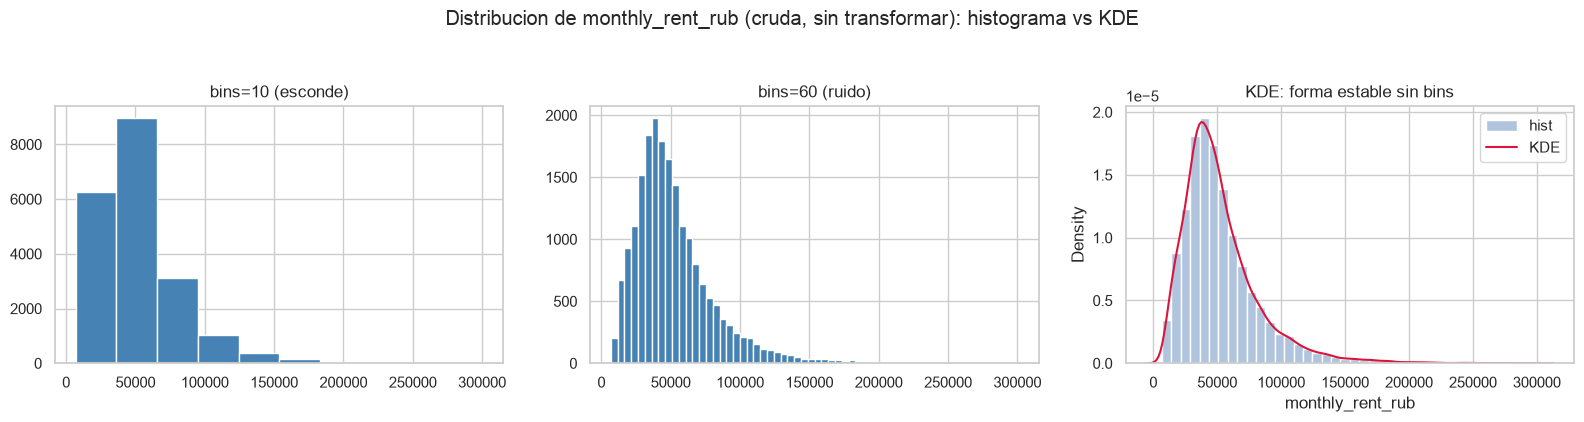

skew: 1.82 (positivo = cola a la derecha, tipico en precios)


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
x = df[TARGET]
axes[0].hist(x, bins=10, color="steelblue", edgecolor="white")
axes[0].set_title("bins=10 (esconde)")
axes[1].hist(x, bins=60, color="steelblue", edgecolor="white")
axes[1].set_title("bins=60 (ruido)")
axes[2].hist(x, bins=40, color="lightsteelblue", edgecolor="white",
             density=True, label="hist")
sns.kdeplot(x=x, ax=axes[2], color="crimson", label="KDE")
axes[2].set_title("KDE: forma estable sin bins")
axes[2].legend()
plt.suptitle(f"Distribucion de {TARGET} (cruda, sin transformar): histograma vs KDE", y=1.05)
plt.tight_layout()
plt.show()
print("skew:", round(float(x.skew()), 3),
      "(positivo = cola a la derecha, tipico en precios)")

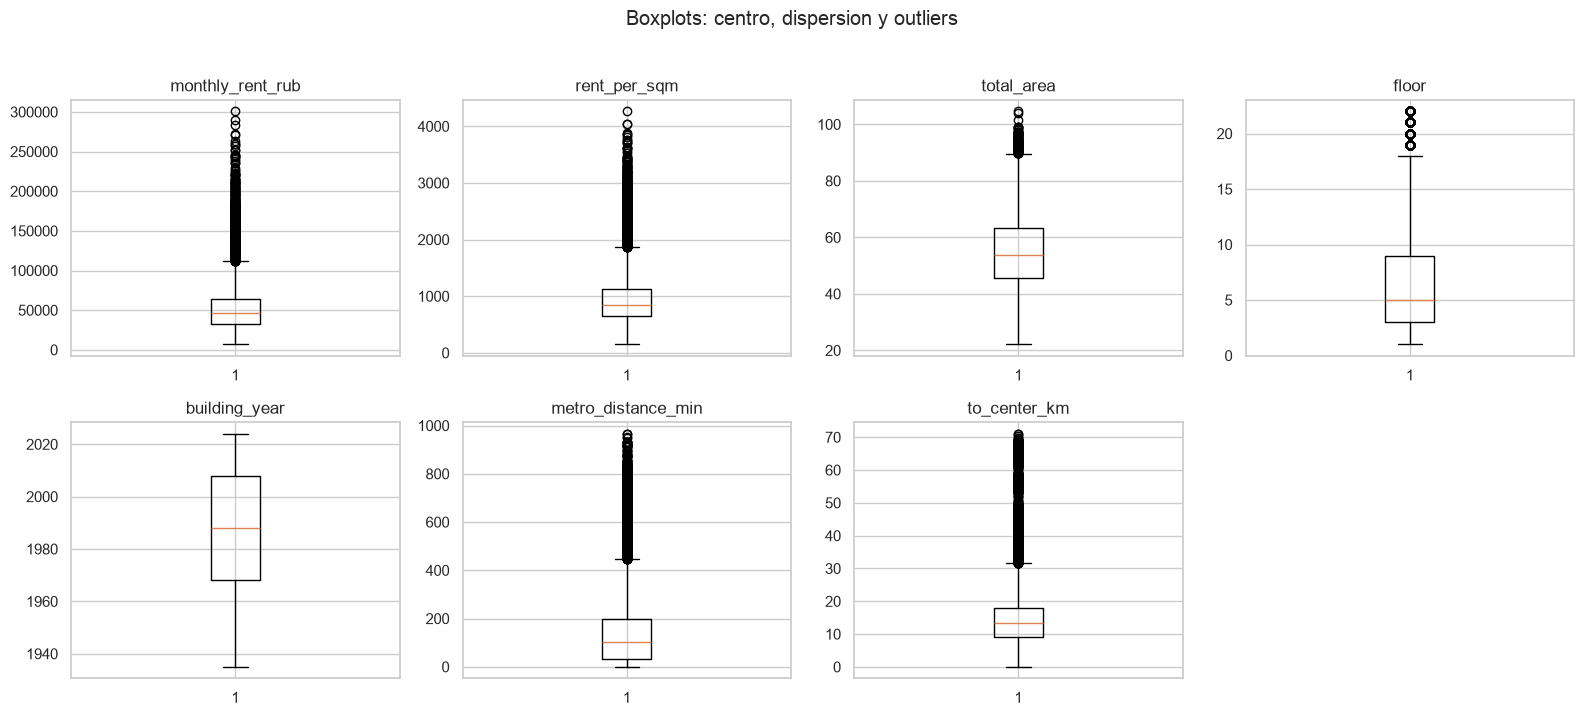

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), KEY_NUM):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
for ax in axes.ravel()[len(KEY_NUM):]:
    ax.axis("off")
plt.suptitle("Boxplots: centro, dispersion y outliers", y=1.02)
plt.tight_layout()
plt.show()

## 3. Univariado categórico: conteos con barras

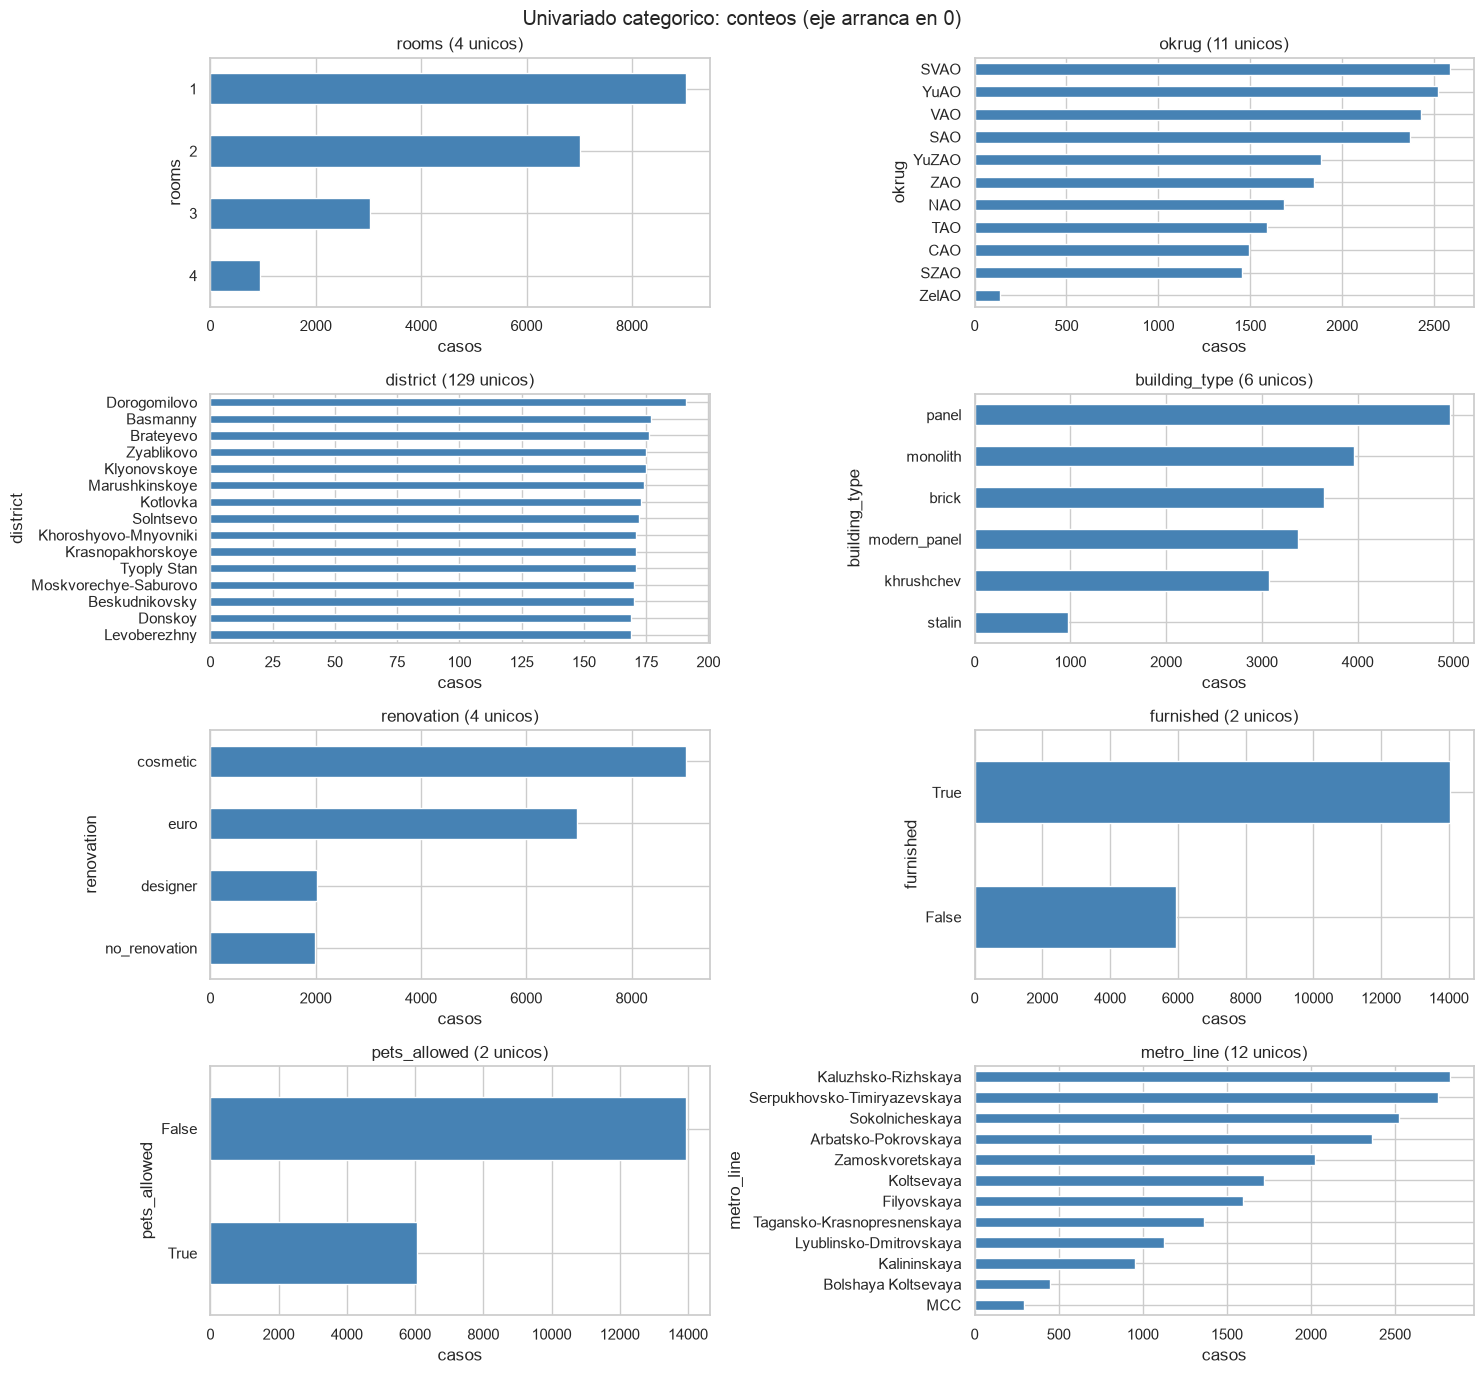

In [10]:
CATS = {"rooms": None, "okrug": None, "district": 15,
        "building_type": None, "renovation": None, "furnished": None,
        "pets_allowed": None, "metro_line": 12}
fig, axes = plt.subplots(4, 2, figsize=(15, 14))
for ax, (col, topn) in zip(axes.ravel(), CATS.items()):
    vc = df[col].astype(str).value_counts()
    if topn:
        vc = vc.head(topn)
    vc.sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"{col} ({df[col].nunique()} unicos)")
    ax.set_xlabel("casos")
for ax in axes.ravel()[len(CATS):]:
    ax.axis("off")
plt.suptitle("Univariado categorico: conteos (eje arranca en 0)")
plt.tight_layout()
plt.show()

## 4. QQ-plot de la variable objetivo

Solo sobre `monthly_rent_rub` **cruda**. El QQ-plot compara los cuantiles de la objetivo contra los de una
normal con su misma media y desvío: si los puntos se apartan de la recta en los
extremos, la cola real es más pesada que la normal. Como referencia se acompaña
con skew, curtosis y Jarque-Bera de la misma variable cruda.


monthly_rent_rub cruda: n=20,000 | media=52,433 | mediana=45,800 | std=30,003 | skew=1.820 | curtosis=5.563 | JB=36,833 (p=0.00e+00)


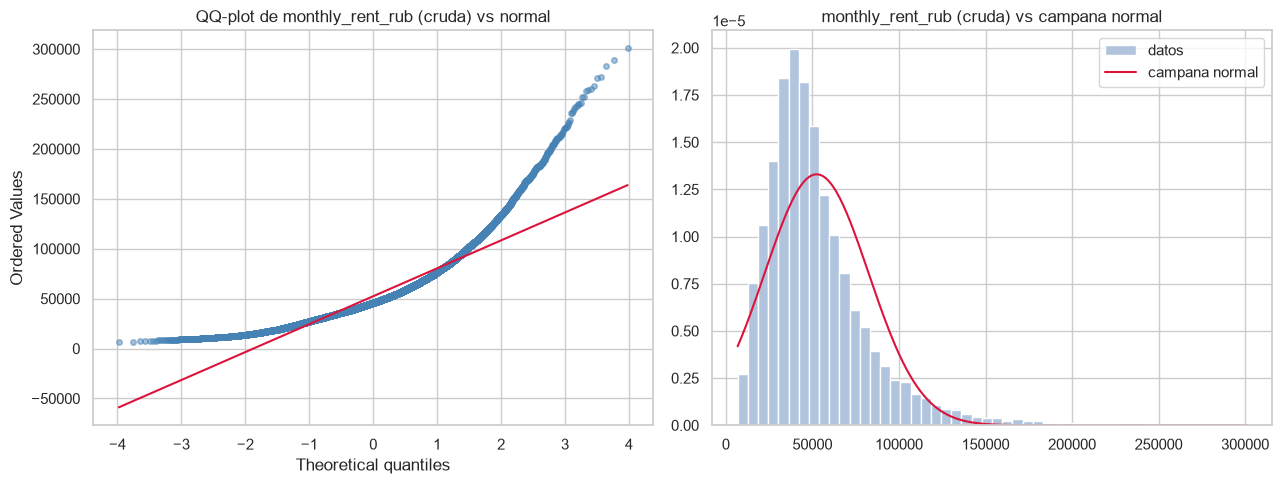

In [11]:
x = df[TARGET].dropna()
jb = stats.jarque_bera(x)
print(f"{TARGET} cruda: n={len(x):,} | media={x.mean():,.0f} | mediana={x.median():,.0f} "
      f"| std={x.std():,.0f} | skew={float(stats.skew(x)):.3f} "
      f"| curtosis={float(stats.kurtosis(x)):.3f} | JB={float(jb.statistic):,.0f} "
      f"(p={float(jb.pvalue):.2e})")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stats.probplot(x, dist="norm", plot=axes[0])
axes[0].get_lines()[0].set(color="steelblue", markersize=4, alpha=0.5)
axes[0].get_lines()[1].set(color="crimson")
axes[0].set_title(f"QQ-plot de {TARGET} (cruda) vs normal")
axes[1].hist(x, bins=50, density=True, color="lightsteelblue",
             edgecolor="white", label="datos")
xs = np.linspace(x.min(), x.max(), 300)
axes[1].plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), color="crimson",
             label="campana normal")
axes[1].set_title(f"{TARGET} (cruda) vs campana normal")
axes[1].legend()
plt.tight_layout()
plt.show()

**Lectura del QQ-plot.** La salida lo confirma con números: `monthly_rent_rub`
cruda tiene media 52.433 RUB contra mediana 45.800 RUB, **skew = 1,82**,
curtosis = 5,56 y Jarque-Bera ≈ 36.833 (p ≈ 0). En el QQ-plot el tramo central
se acerca a la recta pero el **extremo superior se despega muy por encima**:
la cola derecha es mucho más pesada que la normal. Conclusión de esta etapa:
la objetivo **no es normal y no la forzamos a serlo**; queda cruda, sin
normalizar ni transformar. Esta no-normalidad se retoma en el diagnóstico de
outliers (sección 12) y deberá tenerse en cuenta al interpretar residuos más
adelante, sin que eso implique transformar la objetivo.


## 5. Distribuciones según features

Cómo cambia la **forma** de la distribución del alquiler según los valores de
otras variables (no solo la media): violines/cajas por categóricas y densidad
de la objetivo por ambientes y por `okrug`.


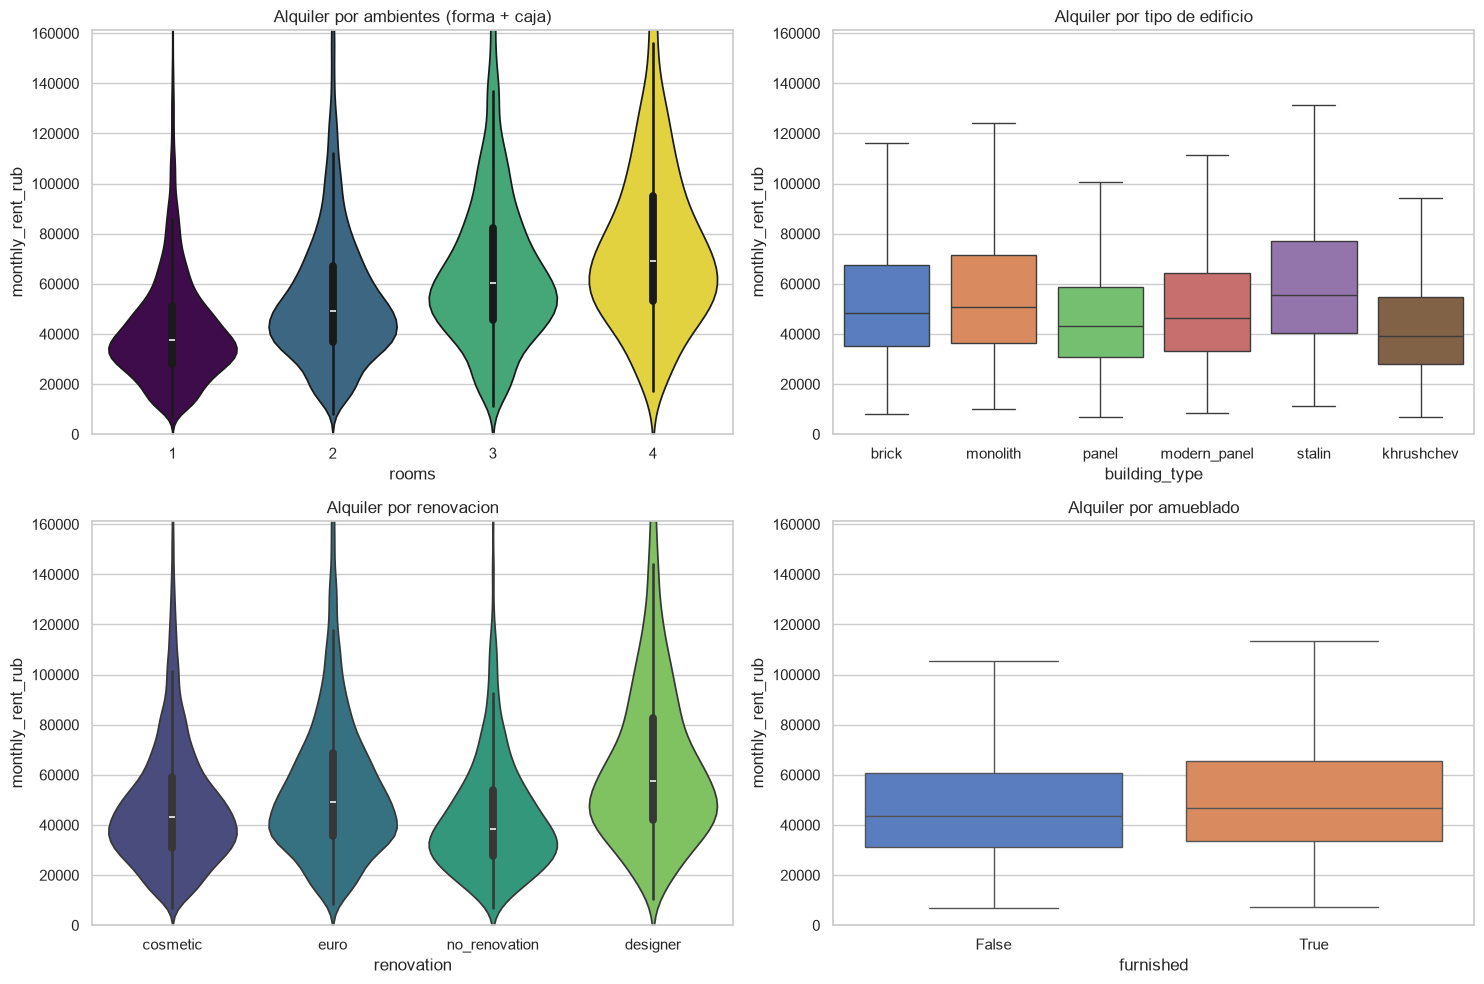

In [12]:
cap99 = df[TARGET].quantile(0.99)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.violinplot(data=df, x="rooms", y=TARGET, ax=axes[0, 0], inner="box",
               hue="rooms", palette="viridis", legend=False)
axes[0, 0].set_ylim(0, cap99)
axes[0, 0].set_title("Alquiler por ambientes (forma + caja)")
sns.boxplot(data=df, x="building_type", y=TARGET, ax=axes[0, 1],
            showfliers=False, hue="building_type", palette="muted", legend=False)
axes[0, 1].set_ylim(0, cap99)
axes[0, 1].set_title("Alquiler por tipo de edificio")
sns.violinplot(data=df, x="renovation", y=TARGET, ax=axes[1, 0], inner="box",
               hue="renovation", palette="viridis", legend=False)
axes[1, 0].set_ylim(0, cap99)
axes[1, 0].set_title("Alquiler por renovacion")
sns.boxplot(data=df, x="furnished", y=TARGET, ax=axes[1, 1],
            showfliers=False, hue="furnished", palette="muted", legend=False)
axes[1, 1].set_ylim(0, cap99)
axes[1, 1].set_title("Alquiler por amueblado")
plt.tight_layout()
plt.show()

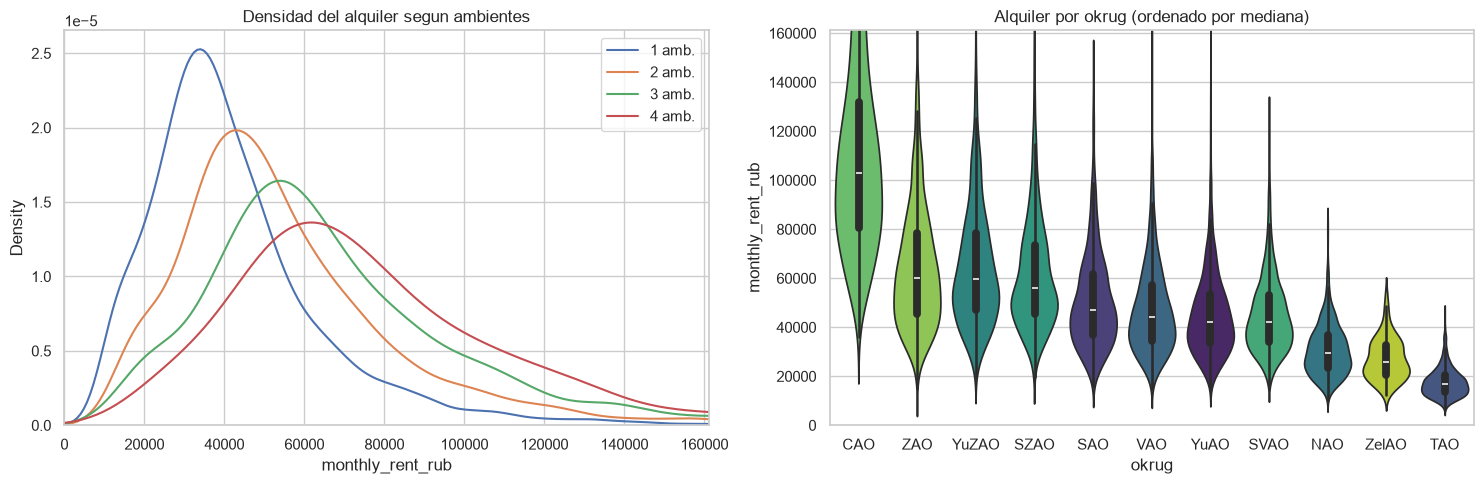

--- distribucion de monthly_rent_rub segun rooms ---


,mean,median,std,count,cv
rooms,,,,,
4,78454.0,69100.0,39761.0,945,0.507
3,67760.0,60200.0,34921.0,3020,0.515
2,55249.0,49100.0,28996.0,7008,0.525
1,42395.0,37700.0,22632.0,9027,0.534


--- distribucion de monthly_rent_rub segun okrug ---


,mean,median,std,count,cv
okrug,,,,,
CAO,110537.0,103100.0,41231.0,1493,0.373
ZAO,64829.0,60100.0,26225.0,1849,0.405
YuZAO,64735.0,59800.0,25022.0,1887,0.387
SZAO,61641.0,56100.0,23430.0,1456,0.380
SAO,51185.0,47200.0,19978.0,2367,0.390
VAO,47534.0,44000.0,18279.0,2431,0.385
YuAO,45497.0,42300.0,17233.0,2520,0.379
SVAO,45123.0,42200.0,15382.0,2588,0.341
NAO,30922.0,29450.0,10557.0,1682,0.341


--- distribucion de monthly_rent_rub segun building_type ---


,mean,median,std,count,cv
building_type,,,,,
stalin,63958.0,55700.0,36374.0,975,0.569
monolith,57925.0,50600.0,32505.0,3958,0.561
brick,54652.0,48200.0,29943.0,3650,0.548
modern_panel,52888.0,46400.0,30128.0,3374,0.570
panel,48554.0,43100.0,27152.0,4967,0.559
khrushchev,44844.0,39100.0,25626.0,3076,0.571


--- distribucion de monthly_rent_rub segun renovation ---


,mean,median,std,count,cv
renovation,,,,,
designer,66475.0,57400.0,37119.0,2021,0.558
euro,55912.0,49300.0,31219.0,6959,0.558
cosmetic,48496.0,43000.0,26799.0,9035,0.553
no_renovation,43858.0,38400.0,24404.0,1985,0.556


--- distribucion de monthly_rent_rub segun furnished ---


,mean,median,std,count,cv
furnished,,,,,
True,53576.0,46900.0,30419.0,14043,0.568
False,49738.0,43400.0,28822.0,5957,0.579


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for amb, sub in df.groupby("rooms"):
    sns.kdeplot(x=sub[TARGET], ax=axes[0], label=f"{amb} amb.", clip=(0, cap99))
axes[0].set_xlim(0, cap99)
axes[0].set_title("Densidad del alquiler segun ambientes")
axes[0].legend()
orden_okrug = df.groupby("okrug")[TARGET].median().sort_values(ascending=False).index
sns.violinplot(data=df, x="okrug", y=TARGET, ax=axes[1], inner="box",
               order=orden_okrug, hue="okrug", palette="viridis", legend=False)
axes[1].set_ylim(0, cap99)
axes[1].set_title("Alquiler por okrug (ordenado por mediana)")
plt.tight_layout()
plt.show()

# La forma tambien se resume en numeros: dispersion dentro de cada grupo
for col in ["rooms", "okrug", "building_type", "renovation", "furnished"]:
    t = (df.groupby(col, observed=True)[TARGET]
         .agg(["mean", "median", "std", "count"]).round(0)
         .sort_values("median", ascending=False))
    t["cv"] = (t["std"] / t["mean"]).round(3)
    print(f"--- distribucion de {TARGET} segun {col} ---")
    display(t)

## 6. Bivariado numérico vs alquiler: scatter + recta lineal simple

Cada panel suma la **recta de regresión lineal simple** sobre la objetivo cruda,
con su `r`, su `R²` y su pendiente. La recta resume la asociación lineal; cuando
la nube es curva o muy dispersa, el `R²` bajo lo dice aunque `r` parezca grande.


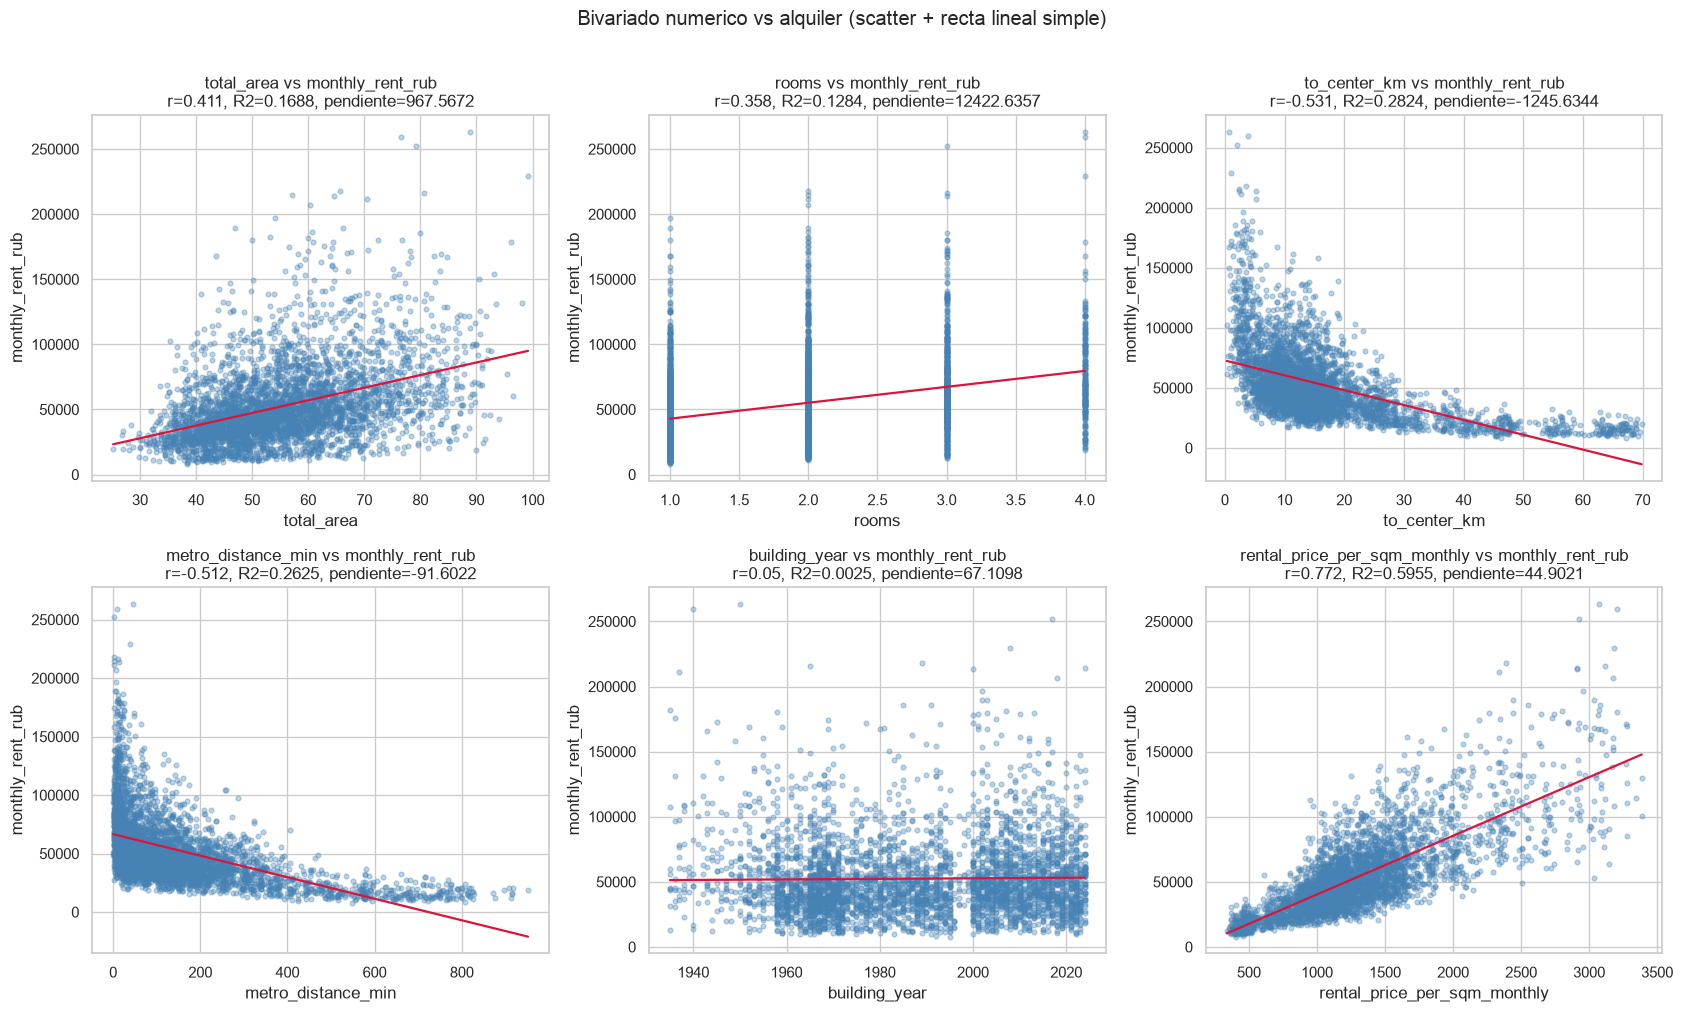

,variable,pendiente,r,R2,p,n
8,rental_price_per_sqm_monthly,44.9021,0.772,0.5955,0.00e+00,20000
2,to_center_km,-1245.6344,-0.531,0.2824,0.00e+00,20000
3,metro_distance_min,-91.6022,-0.512,0.2625,0.00e+00,20000
0,total_area,967.5672,0.411,0.1688,0.00e+00,20000
1,rooms,12422.6357,0.358,0.1284,0.00e+00,20000
6,lat,56936.1573,0.274,0.0750,0.00e+00,20000
7,lon,36921.0472,0.222,0.0495,1.03e-222,20000
4,building_year,67.1098,0.050,0.0025,1.07e-12,20000
5,floor,-34.4748,-0.006,0.0000,4.33e-01,20000


Nota: rent_per_sqm no entra en esta competencia porque deriva de la propia objetivo (fuga); su r se reporta en correlaciones solo como aviso.


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, col in zip(axes.ravel(), ["total_area", "rooms", "to_center_km",
                                  "metro_distance_min", "building_year",
                                  "rental_price_per_sqm_monthly"]):
    scatter_reg(ax, df, col)
for ax in axes.ravel()[6:]:
    ax.axis("off")
plt.suptitle("Bivariado numerico vs alquiler (scatter + recta lineal simple)", y=1.01)
plt.tight_layout()
plt.show()

tabla_reg = pd.DataFrame([reg_simple(df, c) for c in
                          ["total_area", "rooms", "to_center_km", "metro_distance_min",
                           "building_year", "floor", "lat", "lon",
                           "rental_price_per_sqm_monthly"]])
display(tabla_reg.sort_values("R2", ascending=False))
print("Nota: rent_per_sqm no entra en esta competencia porque deriva de la "
      "propia objetivo (fuga); su r se reporta en correlaciones solo como aviso.")

### 6.1 Bivariado categórico vs alquiler: agrupar

In [15]:
for col in ["rooms", "building_type", "renovation", "furnished", "okrug"]:
    t = (df.groupby(col, observed=True)[TARGET]
         .agg(["mean", "median", "count"]).round(0)
         .sort_values("mean", ascending=False))
    print(f"--- {col} ---")
    display(t)

--- rooms ---


,mean,median,count
rooms,,,
4,78454.0,69100.0,945
3,67760.0,60200.0,3020
2,55249.0,49100.0,7008
1,42395.0,37700.0,9027


--- building_type ---


,mean,median,count
building_type,,,
stalin,63958.0,55700.0,975
monolith,57925.0,50600.0,3958
brick,54652.0,48200.0,3650
modern_panel,52888.0,46400.0,3374
panel,48554.0,43100.0,4967
khrushchev,44844.0,39100.0,3076


--- renovation ---


,mean,median,count
renovation,,,
designer,66475.0,57400.0,2021
euro,55912.0,49300.0,6959
cosmetic,48496.0,43000.0,9035
no_renovation,43858.0,38400.0,1985


--- furnished ---


,mean,median,count
furnished,,,
True,53576.0,46900.0,14043
False,49738.0,43400.0,5957


--- okrug ---


,mean,median,count
okrug,,,
CAO,110537.0,103100.0,1493
ZAO,64829.0,60100.0,1849
YuZAO,64735.0,59800.0,1887
SZAO,61641.0,56100.0,1456
SAO,51185.0,47200.0,2367
VAO,47534.0,44000.0,2431
YuAO,45497.0,42300.0,2520
SVAO,45123.0,42200.0,2588
NAO,30922.0,29450.0,1682


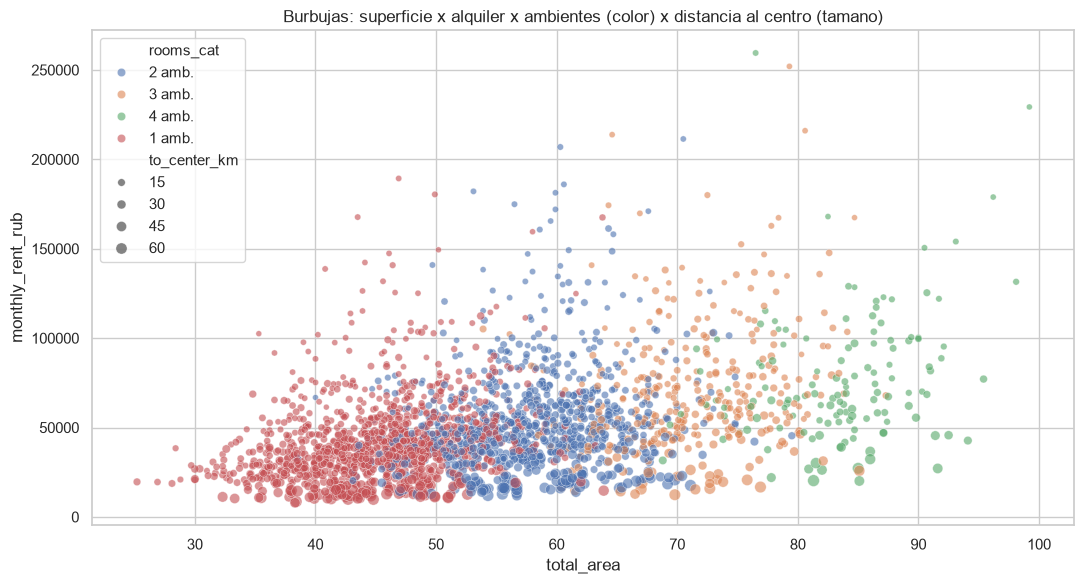

In [16]:
bub = df.sample(min(2500, len(df)), random_state=42).copy()
bub["rooms_cat"] = (pd.to_numeric(bub["rooms"], errors="coerce")
                    .round(0).astype("Int64").astype(str) + " amb.")
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=bub, x="total_area", y=TARGET, hue="rooms_cat",
                size="to_center_km", alpha=0.6, ax=ax)
ax.set_title("Burbujas: superficie x alquiler x ambientes (color) "
             "x distancia al centro (tamano)")
plt.tight_layout()
plt.show()

## 7. Correlación y colinealidad 

Pearson sobre la objetivo cruda. Los pares con |r| alto entre predictoras
anticipan colinealidad; el detalle por bloque (con VIF) va en las secciones
8 a 10.


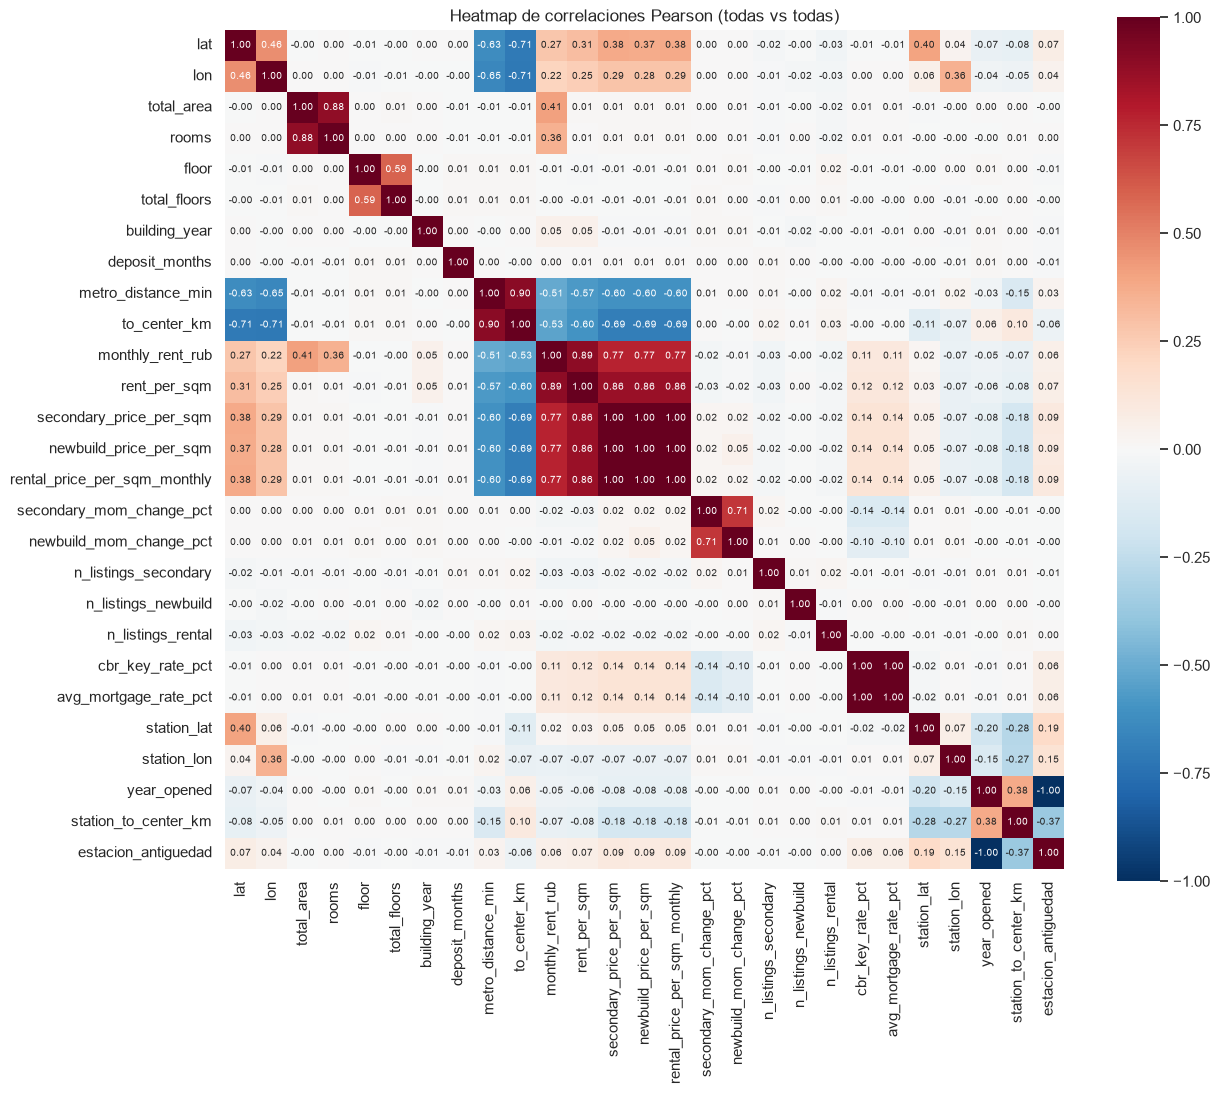

In [17]:
corr = num.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=ax,
            annot_kws={"size": 7})
ax.set_title("Heatmap de correlaciones Pearson (todas vs todas)")
plt.tight_layout()
plt.show()

In [18]:
tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
st = tri.stack().dropna()
pairs = pd.DataFrame({"r": st, "abs_r": st.abs()}).round(3)
pairs = pairs.sort_values("abs_r", ascending=False)
print("--- Top 15 pares por |r| (colinealidad candidata) ---")
display(pairs.head(15))
st_t = corr[TARGET].drop(TARGET).dropna()
tcorr = pd.DataFrame({"r": st_t, "abs_r": st_t.abs()}).round(3)
tcorr = tcorr.sort_values("abs_r", ascending=False)
print(f"--- Correlacion con {TARGET} ---")
display(tcorr)

--- Top 15 pares por |r| (colinealidad candidata) ---


r  abs_r
cbr_key_rate_pct         avg_mortgage_rate_pct         1.000  1.000
secondary_price_per_sqm  rental_price_per_sqm_monthly  1.000  1.000
newbuild_price_per_sqm   rental_price_per_sqm_monthly  0.998  0.998
secondary_price_per_sqm  newbuild_price_per_sqm        0.998  0.998
year_opened              estacion_antiguedad          -0.997  0.997
metro_distance_min       to_center_km                  0.904  0.904
monthly_rent_rub         rent_per_sqm                  0.893  0.893
total_area               rooms                         0.883  0.883
rent_per_sqm             rental_price_per_sqm_monthly  0.863  0.863
                         secondary_price_per_sqm       0.863  0.863
                         newbuild_price_per_sqm        0.861  0.861
monthly_rent_rub         secondary_price_per_sqm       0.772  0.772
                         rental_price_per_sqm_monthly  0.772  0.772
                         newbuild_price_per_sqm        0.770  0.770
secondary_mom_change_pct newbuild_mom_change_pct       0.714  0.714

--- Correlacion con monthly_rent_rub ---


,r,abs_r
rent_per_sqm,0.893,0.893
rental_price_per_sqm_monthly,0.772,0.772
secondary_price_per_sqm,0.772,0.772
newbuild_price_per_sqm,0.770,0.770
to_center_km,-0.531,0.531
metro_distance_min,-0.512,0.512
total_area,0.411,0.411
rooms,0.358,0.358
lat,0.274,0.274
lon,0.222,0.222


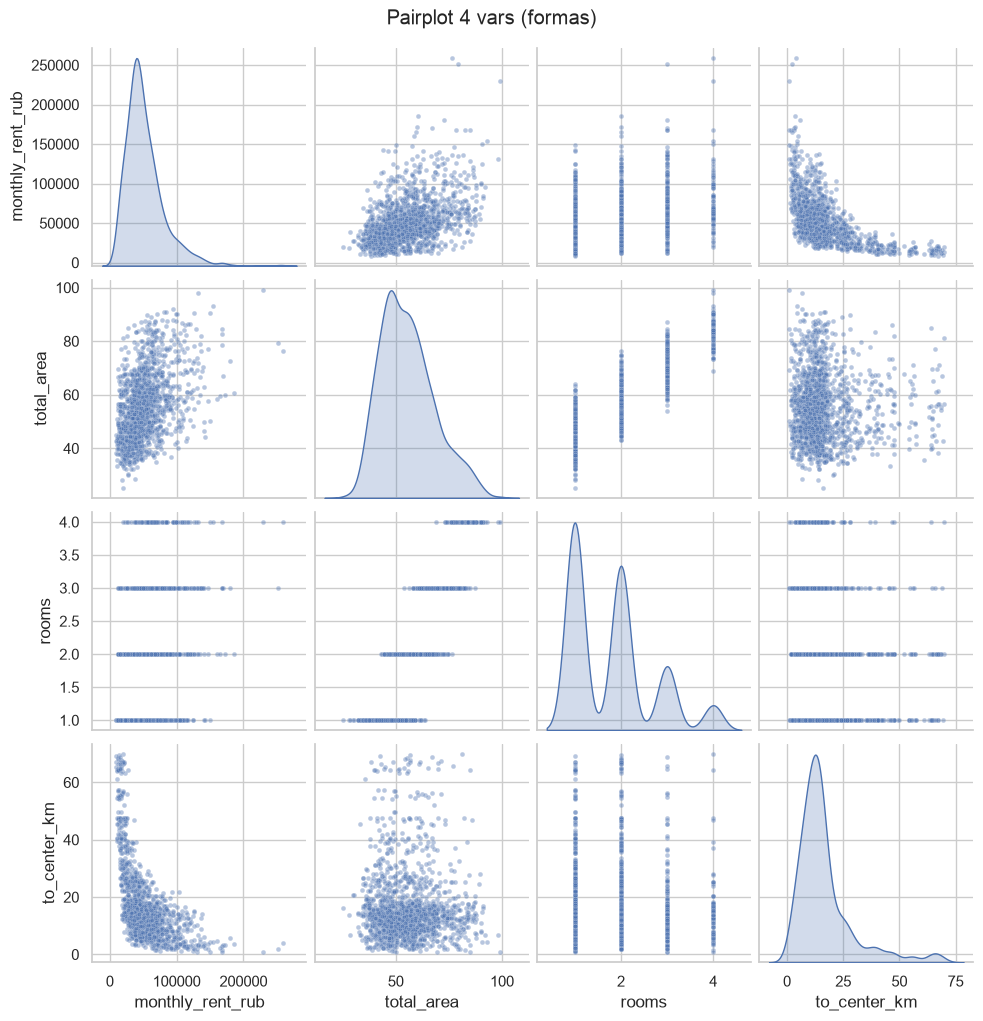

In [19]:
pp_vars = [TARGET, "total_area", "rooms", "to_center_km"]
g = sns.pairplot(df.sample(min(1500, len(df)), random_state=42)[pp_vars],
                 diag_kind="kde", plot_kws={"alpha": 0.4, "s": 12})
g.fig.suptitle("Pairplot 4 vars (formas)", y=1.02)
plt.show()

## 8. Heterogeneidad geográfica

Preguntas de este bloque: **¿cuántos valores hay y cuánto varía** el alquiler
entre lugares? ¿Qué tanto se explican entre sí las variables geográficas
(colinealidad, VIF)? ¿Cuál es la geográfica **más significativa** para la objetivo?

Variables del bloque: `district` (129), `okrug` (11), `lat`, `lon`,
`to_center_km` del aviso, y el contexto distrito-mes del join
(`rental_price_per_sqm_monthly`, precios de venta por m2, volumen de avisos).
`rent_per_sqm` no compite: deriva de la objetivo.


distritos: 129 | okrugs: 11 | estaciones: 104 | lineas: 12
lat: 55.230 -> 56.013 | lon: 36.702 -> 37.908 | to_center_km: 0.02 -> 71.06
--- Alquiler por okrug (heterogeneidad entre grandes zonas) ---


,n,media,mediana,std,p25,p75
okrug,,,,,,
CAO,1493,110537.0,103100.0,41231.0,80700.0,132100.0
ZAO,1849,64829.0,60100.0,26225.0,45300.0,78600.0
YuZAO,1887,64735.0,59800.0,25022.0,46850.0,78350.0
SZAO,1456,61641.0,56100.0,23430.0,45475.0,73500.0
SAO,2367,51185.0,47200.0,19978.0,36750.0,61600.0
VAO,2431,47534.0,44000.0,18279.0,34500.0,57200.0
YuAO,2520,45497.0,42300.0,17233.0,33500.0,53700.0
SVAO,2588,45123.0,42200.0,15382.0,34000.0,53225.0
NAO,1682,30922.0,29450.0,10557.0,23225.0,36975.0


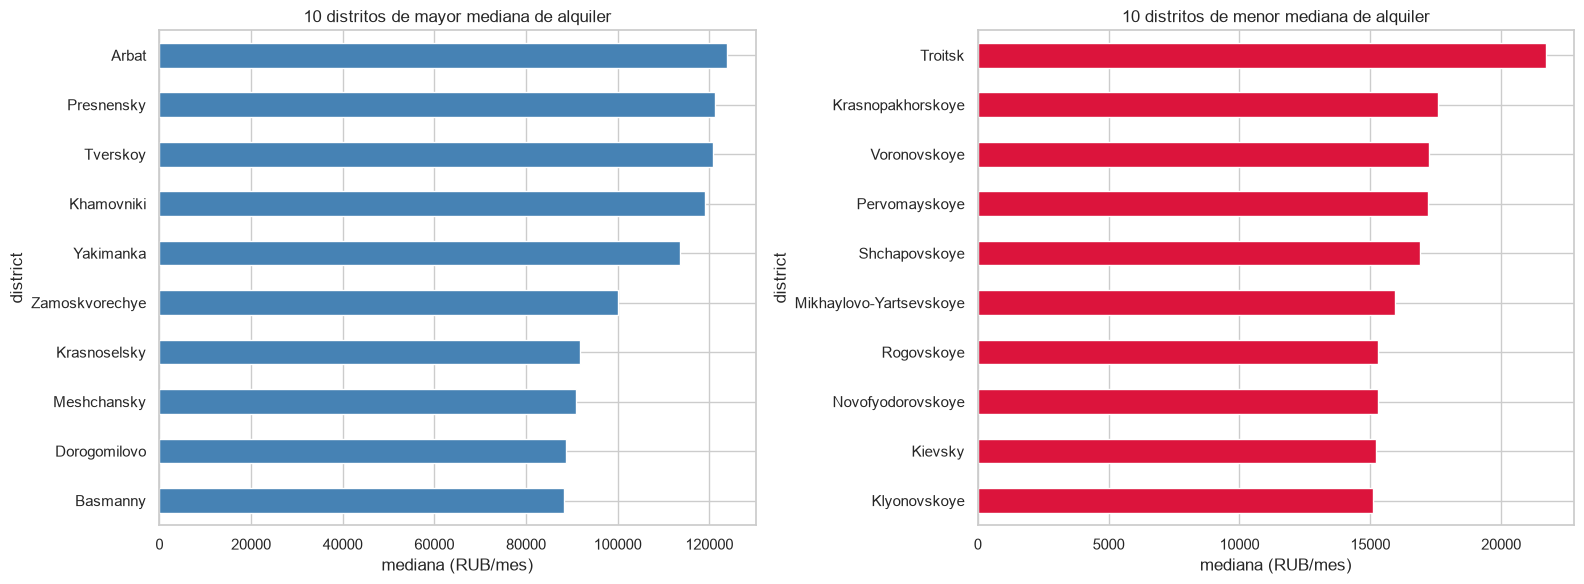

mediana distrital: min=15,100 | max=123,900 | ratio max/min=8.2x
eta2 okrug   = 0.492  (varianza explicada por el okrug)
eta2 district= 0.604  (varianza explicada por el distrito)
eta2 metro_line = 0.008


In [20]:
print(f"distritos: {df['district'].nunique()} | okrugs: {df['okrug'].nunique()} "
      f"| estaciones: {df['metro_station'].nunique()} | lineas: {df['metro_line'].nunique()}")
print(f"lat: {df['lat'].min():.3f} -> {df['lat'].max():.3f} | "
      f"lon: {df['lon'].min():.3f} -> {df['lon'].max():.3f} | "
      f"to_center_km: {df['to_center_km'].min():.2f} -> {df['to_center_km'].max():.2f}")

por_okrug = (df.groupby("okrug")[TARGET]
             .agg(["count", "mean", "median", "std",
                   lambda s: s.quantile(0.25), lambda s: s.quantile(0.75)])
             .round(0))
por_okrug.columns = ["n", "media", "mediana", "std", "p25", "p75"]
por_okrug = por_okrug.sort_values("mediana", ascending=False)
print("--- Alquiler por okrug (heterogeneidad entre grandes zonas) ---")
display(por_okrug)

por_distrito = (df.groupby("district")[TARGET]
                .agg(["count", "mean", "median", "std"]).round(0)
                .sort_values("median", ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
por_distrito.head(10).sort_values("median")["median"].plot.barh(
    ax=axes[0], color="steelblue")
axes[0].set_title("10 distritos de mayor mediana de alquiler")
axes[0].set_xlabel("mediana (RUB/mes)")
por_distrito.tail(10).sort_values("median")["median"].plot.barh(
    ax=axes[1], color="crimson")
axes[1].set_title("10 distritos de menor mediana de alquiler")
axes[1].set_xlabel("mediana (RUB/mes)")
plt.tight_layout()
plt.show()
print(f"mediana distrital: min={por_distrito['median'].min():,.0f} | "
      f"max={por_distrito['median'].max():,.0f} | "
      f"ratio max/min={por_distrito['median'].max() / por_distrito['median'].min():.1f}x")

# Cuanto explica cada nivel geografico: eta2 (varianza entre grupos / total)
print(f"eta2 okrug   = {eta2(df, 'okrug'):.3f}  (varianza explicada por el okrug)")
print(f"eta2 district= {eta2(df, 'district'):.3f}  (varianza explicada por el distrito)")
print(f"eta2 metro_line = {eta2(df, 'metro_line'):.3f}")

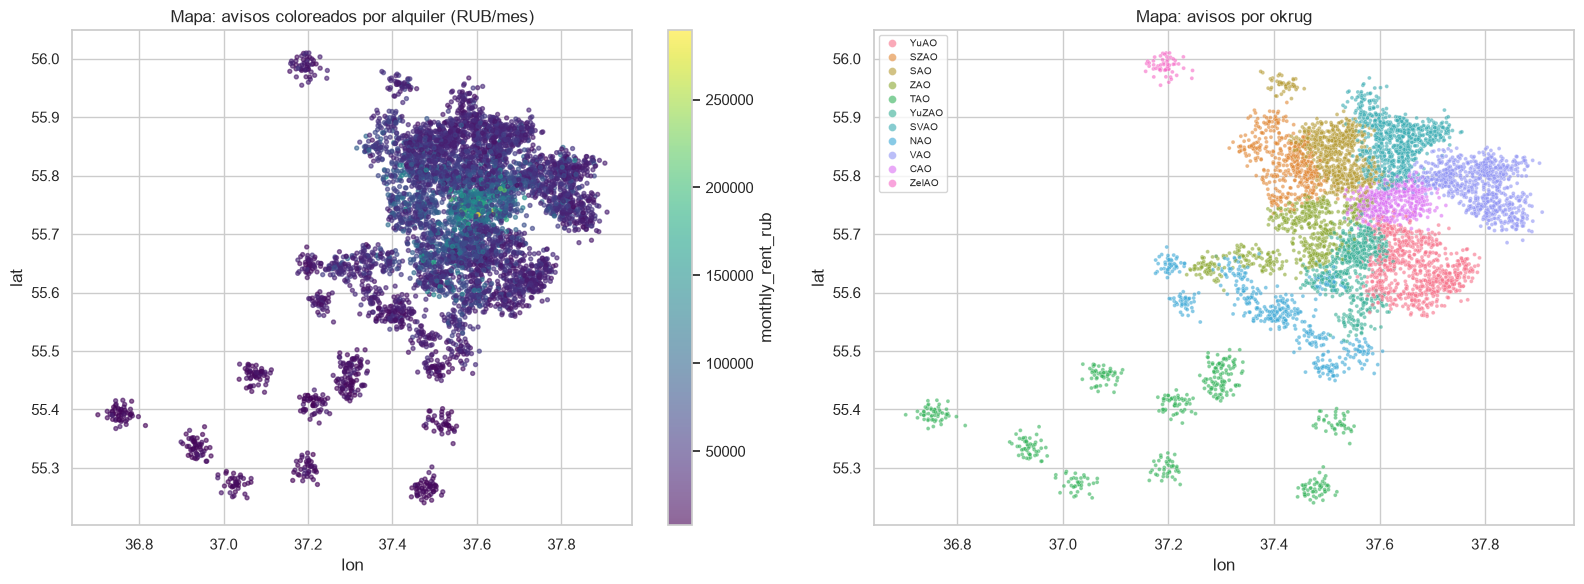

In [21]:
smap = df.sample(min(6000, len(df)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sc = axes[0].scatter(smap["lon"], smap["lat"], c=smap[TARGET], s=8,
                     cmap="viridis", alpha=0.6)
axes[0].set_xlabel("lon")
axes[0].set_ylabel("lat")
axes[0].set_title("Mapa: avisos coloreados por alquiler (RUB/mes)")
plt.colorbar(sc, ax=axes[0], label=TARGET)
sns.scatterplot(data=smap, x="lon", y="lat", hue="okrug", s=8, alpha=0.6, ax=axes[1])
axes[1].set_title("Mapa: avisos por okrug")
axes[1].legend(fontsize=7, markerscale=2)
plt.tight_layout()
plt.show()

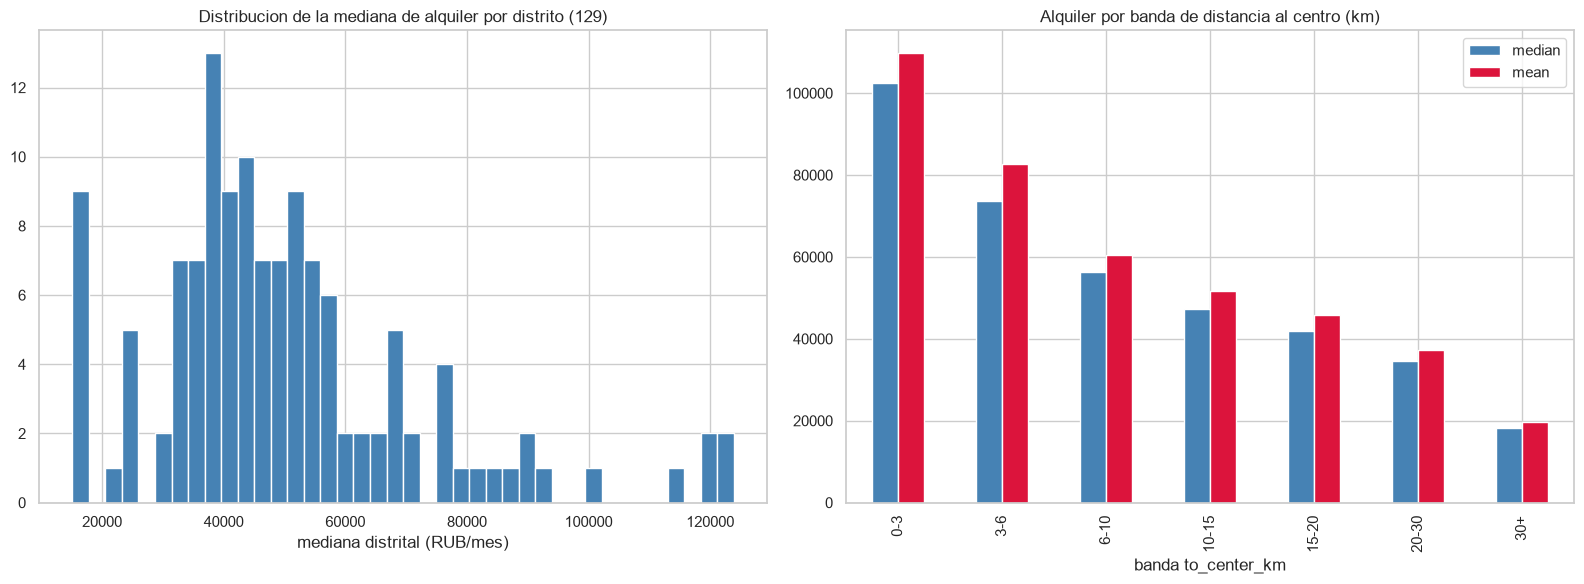

,median,mean,count
to_center_km,,,
0-3,102500.0,109809.0,787
3-6,73650.0,82707.0,1798
6-10,56300.0,60583.0,3457
10-15,47200.0,51645.0,6303
15-20,42000.0,45828.0,3483
20-30,34650.0,37199.0,2110
30+,18300.0,19626.0,2062


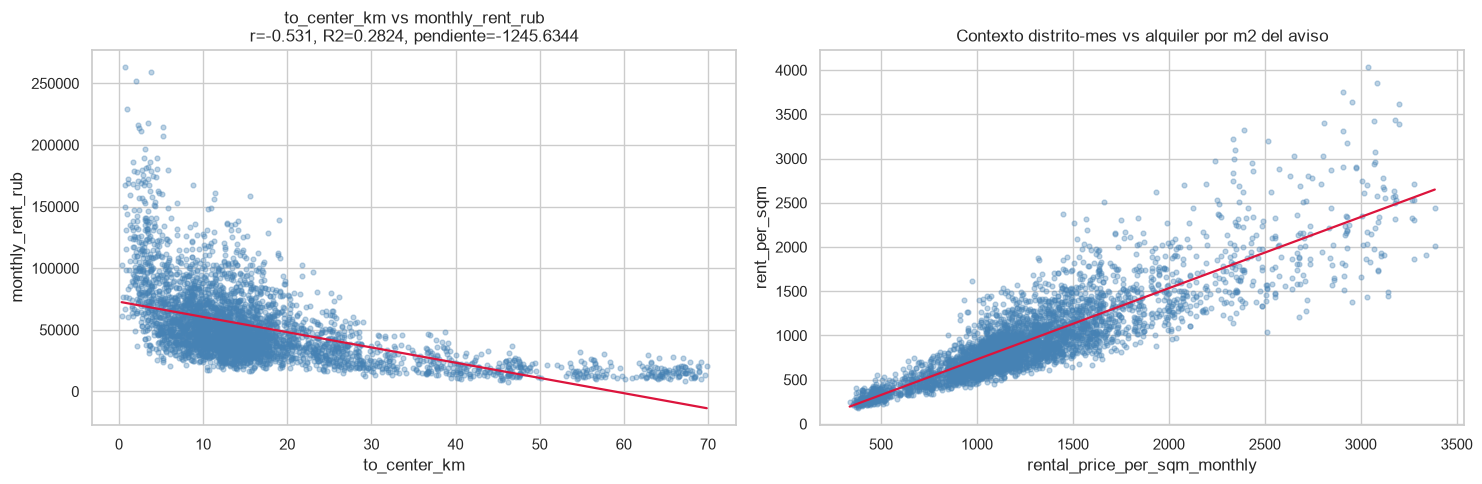

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
por_distrito["median"].hist(bins=40, ax=axes[0], color="steelblue", edgecolor="white")
axes[0].set_title("Distribucion de la mediana de alquiler por distrito (129)")
axes[0].set_xlabel("mediana distrital (RUB/mes)")
bandas = pd.cut(df["to_center_km"], bins=[0, 3, 6, 10, 15, 20, 30, 80],
                labels=["0-3", "3-6", "6-10", "10-15", "15-20", "20-30", "30+"])
tb = df.groupby(bandas, observed=True)[TARGET].agg(["median", "mean", "count"]).round(0)
tb[["median", "mean"]].plot.bar(ax=axes[1], color=["steelblue", "crimson"])
axes[1].set_title("Alquiler por banda de distancia al centro (km)")
axes[1].set_xlabel("banda to_center_km")
plt.tight_layout()
plt.show()
display(tb)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
scatter_reg(axes[0], df, "to_center_km")
scatter_reg(axes[1], df, "rental_price_per_sqm_monthly", y="rent_per_sqm")
axes[1].set_title("Contexto distrito-mes vs alquiler por m2 del aviso")
plt.tight_layout()
plt.show()

--- Correlaciones dentro del bloque geografico (heatmap) ---


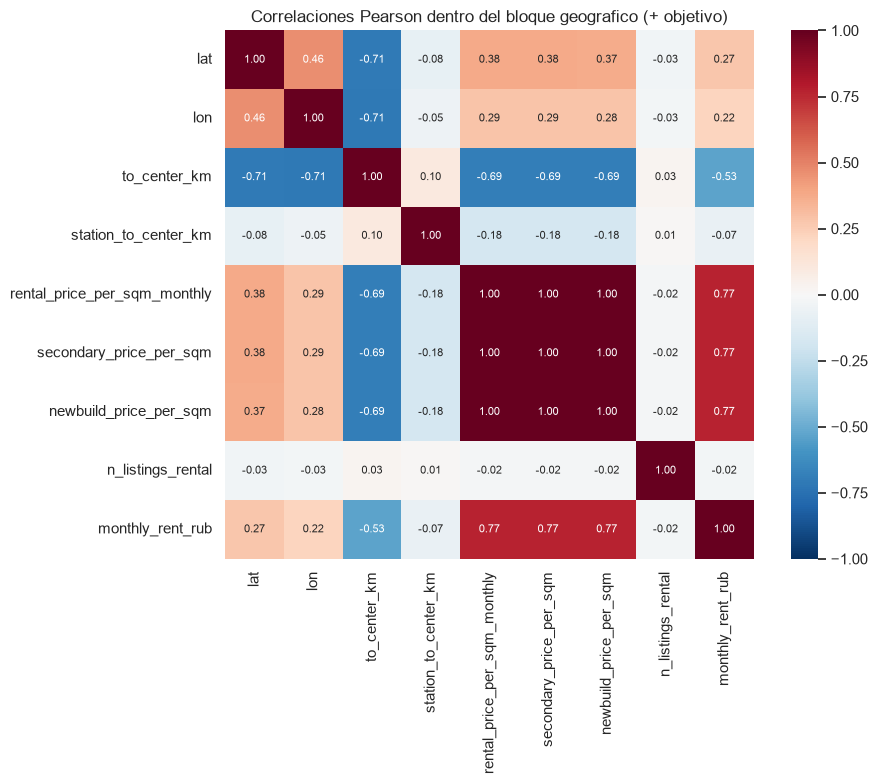

--- VIF del bloque geografico (sin la objetivo) ---


,variable,VIF
5,secondary_price_per_sqm,2736731.42
4,rental_price_per_sqm_monthly,2736399.64
6,newbuild_price_per_sqm,232.39
2,to_center_km,6.83
1,lon,2.55
0,lat,2.19
3,station_to_center_km,1.04
7,n_listings_rental,1.00


--- Significancia univariada (regresion simple contra la objetivo cruda) ---


,variable,pendiente,r,R2,p,n
4,rental_price_per_sqm_monthly,44.9021,0.772,0.5955,0.00e+00,20000
5,secondary_price_per_sqm,0.1871,0.772,0.5955,0.00e+00,20000
6,newbuild_price_per_sqm,0.1691,0.770,0.5923,0.00e+00,20000
2,to_center_km,-1245.6344,-0.531,0.2824,0.00e+00,20000
0,lat,56936.1573,0.274,0.0750,0.00e+00,20000
1,lon,36921.0472,0.222,0.0495,1.03e-222,20000
3,station_to_center_km,-441.9153,-0.071,0.0051,7.33e-24,20000
7,n_listings_rental,-22.4357,-0.024,0.0006,7.45e-04,20000


--- Como referencia categorica: eta2 district=0.604, okrug=0.492 ---


In [23]:
GEO_NUM = ["lat", "lon", "to_center_km", "station_to_center_km",
           "rental_price_per_sqm_monthly", "secondary_price_per_sqm",
           "newbuild_price_per_sqm", "n_listings_rental"]
print("--- Correlaciones dentro del bloque geografico (heatmap) ---")
corr_geo = df[GEO_NUM + [TARGET]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_geo, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlaciones Pearson dentro del bloque geografico (+ objetivo)")
plt.tight_layout()
plt.show()
print("--- VIF del bloque geografico (sin la objetivo) ---")
display(vif_tabla(df, GEO_NUM))
print("--- Significancia univariada (regresion simple contra la objetivo cruda) ---")
geo_reg = pd.DataFrame([reg_simple(df, c) for c in GEO_NUM])
display(geo_reg.sort_values("R2", ascending=False))
print(f"--- Como referencia categorica: eta2 district={eta2(df, 'district'):.3f}, "
      f"okrug={eta2(df, 'okrug'):.3f} ---")

**Lectura geográfica.** La heterogeneidad es fuerte y medible en los dos
niveles. Entre `okrug`: la mediana va de **103.100 RUB en CAO a 16.800 RUB en
TAO** (≈6×). Entre los 129 distritos: la mediana distrital va de **15.100 a
123.900 RUB (ratio 8,2×)**, con Arbat, Presnensky y Tverskoy arriba. El `eta2`
lo resume: el distrito explica el **60,4%** de la varianza del alquiler y el
`okrug` el **49,2%**; el resto es variación *dentro* del mismo lugar. Por banda
de distancia, la mediana cae de 102.500 RUB (0–3 km) a 18.300 RUB (30+ km), y
la recta simple de `to_center_km` da r = −0,53 (R² = 0,28).

**Colinealidad y variable más significativa del bloque.** Las tres variables de
precio del contexto distrito-mes son prácticamente la misma información:
correlaciones de **0,998–1,000** entre sí y **VIF de millones** para
`rental_price_per_sqm_monthly` y `secondary_price_per_sqm` (232 para
`newbuild_price_per_sqm`); alcanza con **una** de ellas. Esa variable de nivel
distrital-mes es la geográfica más significativa en regresión simple
(**R² = 0,60**, r = 0,77), muy por encima de `to_center_km` (R² = 0,28) y de
`lat`/`lon` crudas (R² = 0,08 / 0,05), que solo resumen posición. Advertencia
para el objetivo futuro: el contexto del distrito-mes es contemporáneo al
aviso, así que al predecir meses futuros habrá que usarlo rezagado o
proyectado, nunca el del mes a predecir como si ya se conociera.


## 9. Superficie y habitaciones

Preguntas: ¿cómo se reparte la superficie según ambientes? ¿Qué tanto se
explican entre sí (colinealidad, VIF)? ¿Cuál es la más significativa?

Variables: `total_area`, `rooms`, `floor`, `total_floors` (y `rent_per_sqm`
solo como referencia, porque deriva de la objetivo: **fuga**, no predictora).


--- Superficie segun ambientes ---


,count,mean,median,std,min,max
rooms,,,,,,
1,9027,45.0,45.1,6.0,22.1,66.0
2,7008,58.1,58.1,6.0,37.6,84.3
3,3020,71.1,70.9,5.9,51.0,88.9
4,945,83.9,84.0,6.1,66.3,104.6


--- Superficie por ambiente (total_area / rooms) ---


,mean,median,std
rooms,,,
1,45.0,45.1,6.0
2,29.0,29.0,3.0
3,23.7,23.6,2.0
4,21.0,21.0,1.5


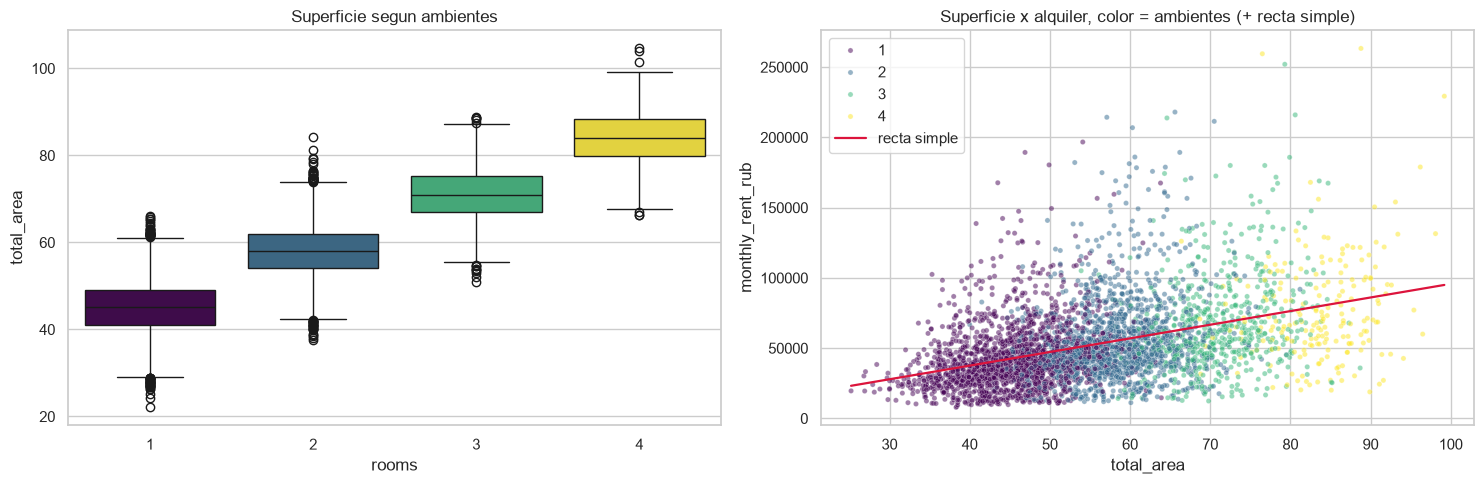

--- Alquiler por banda de superficie (m2) ---


,count,mean,median,std
total_area,,,,
<35,421,29362.0,26800.0,14325.0
35-45,4159,38938.0,35000.0,20197.0
45-55,6180,46778.0,41800.0,23942.0
55-65,4848,57074.0,50800.0,29315.0
65-80,3489,67717.0,60100.0,34660.0
80+,903,80073.0,71300.0,41251.0


In [24]:
print("--- Superficie segun ambientes ---")
display(df.groupby("rooms")["total_area"]
        .agg(["count", "mean", "median", "std", "min", "max"]).round(1))
df["area_por_ambiente"] = df["total_area"] / df["rooms"]
print("--- Superficie por ambiente (total_area / rooms) ---")
display(df.groupby("rooms")["area_por_ambiente"].agg(["mean", "median", "std"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="rooms", y="total_area", ax=axes[0],
            hue="rooms", palette="viridis", legend=False)
axes[0].set_title("Superficie segun ambientes")
s4 = df.sample(min(4000, len(df)), random_state=42)
sns.scatterplot(data=s4, x="total_area", y=TARGET, hue="rooms", palette="viridis",
                alpha=0.5, s=14, ax=axes[1])
b, a = np.polyfit(s4["total_area"], s4[TARGET], 1)
xs = np.linspace(s4["total_area"].min(), s4["total_area"].max(), 50)
axes[1].plot(xs, a + b * xs, color="crimson", lw=1.6, label="recta simple")
axes[1].set_title("Superficie x alquiler, color = ambientes (+ recta simple)")
axes[1].legend()
plt.tight_layout()
plt.show()

bins_area = pd.cut(df["total_area"], bins=[0, 35, 45, 55, 65, 80, 200],
                   labels=["<35", "35-45", "45-55", "55-65", "65-80", "80+"])
print("--- Alquiler por banda de superficie (m2) ---")
display(df.groupby(bins_area, observed=True)[TARGET]
        .agg(["count", "mean", "median", "std"]).round(0))

--- Correlaciones dentro del bloque superficie/habitaciones (heatmap) ---


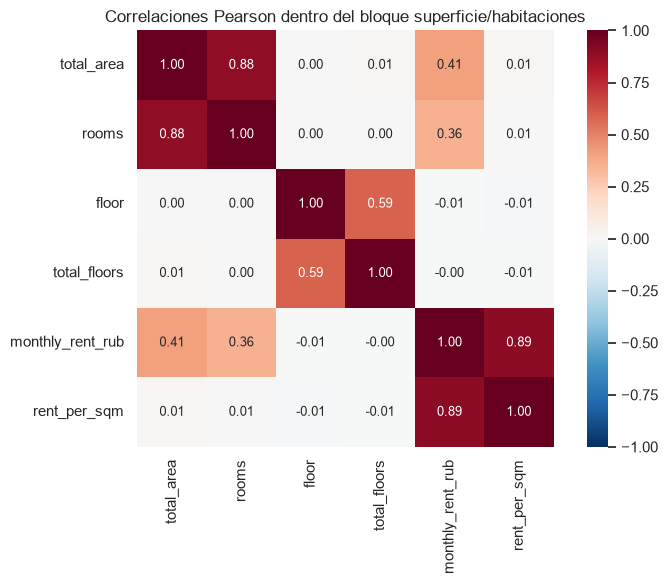

--- VIF del bloque (sin la objetivo; rent_per_sqm excluida por fuga) ---


,variable,VIF
0,total_area,4.54
1,rooms,4.54
2,floor,1.54
3,total_floors,1.54


--- Significancia univariada (regresion simple contra la objetivo cruda) ---


,variable,pendiente,r,R2,p,n
0,total_area,967.5672,0.411,0.1688,0.00e+00,20000
1,rooms,12422.6357,0.358,0.1284,0.00e+00,20000
2,floor,-34.4748,-0.006,0.0000,4.33e-01,20000
3,total_floors,-12.7238,-0.002,0.0000,7.33e-01,20000


referencia con fuga: r(rent_per_sqm, objetivo) = 0.893 (deriva de la objetivo, no compite)
eta2 rooms = 0.129


In [25]:
SUP_NUM = ["total_area", "rooms", "floor", "total_floors"]
print("--- Correlaciones dentro del bloque superficie/habitaciones (heatmap) ---")
corr_sup = df[SUP_NUM + [TARGET, "rent_per_sqm"]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_sup, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=ax, annot_kws={"size": 9})
ax.set_title("Correlaciones Pearson dentro del bloque superficie/habitaciones")
plt.tight_layout()
plt.show()
print("--- VIF del bloque (sin la objetivo; rent_per_sqm excluida por fuga) ---")
display(vif_tabla(df, SUP_NUM))
print("--- Significancia univariada (regresion simple contra la objetivo cruda) ---")
sup_reg = pd.DataFrame([reg_simple(df, c) for c in SUP_NUM])
display(sup_reg.sort_values("R2", ascending=False))
print(f"referencia con fuga: r(rent_per_sqm, objetivo) = "
      f"{df['rent_per_sqm'].corr(df[TARGET]):.3f} (deriva de la objetivo, no compite)")
print(f"eta2 rooms = {eta2(df, 'rooms'):.3f}")

**Lectura superficie/habitaciones.** Superficie y ambientes crecen juntas y
de forma muy regular: la superficie media pasa de 45,0 m² (1 ambiente) a
83,9 m² (4 ambientes), con correlación **r = 0,88** entre `total_area` y
`rooms` y **VIF = 4,54 para ambas** (vigilar: comparten gran parte de la
señal). La superficie por ambiente, en cambio, baja de 45,0 a 21,0 m²: los
ambientes agregan metros, pero cada vez menos por ambiente.

**Variable más significativa del bloque.** En regresión simple contra la
objetivo cruda gana `total_area` (**R² = 0,17**, pendiente ≈ +968 RUB por m²)
sobre `rooms` (R² = 0,13; `eta2` de rooms = 0,13). `floor` y `total_floors`
no aportan en forma lineal simple (R² ≈ 0,00, p no significativo para `floor`:
0,43). Y ojo con `rent_per_sqm`: su r = 0,89 **contiene** a la objetivo
(es objetivo/superficie), así que no es una explicación, es una identidad —
queda fuera de la competencia por fuga.


## 10. Transporte

Preguntas: ¿cómo varía el alquiler con el acceso al metro? ¿Qué tanto se
explican entre sí las variables de transporte (colinealidad, VIF)? ¿Cuál es
la más significativa?

Variables: `metro_distance_min`, `metro_station` (104), `metro_line` (12),
`station_to_center_km`, `estacion_antiguedad` (derivada de `year_opened`) y,
como puente con geografía, `to_center_km` del aviso.


estaciones: 104 | lineas: 12
--- Alquiler por linea de metro ---


,count,mean,median,std
metro_line,,,,
Tagansko-Krasnopresnenskaya,1364,54752.0,47600.0,31855.0
Koltsevaya,1719,59152.0,47500.0,40248.0
Sokolnicheskaya,2524,54423.0,47200.0,31613.0
Kaluzhsko-Rizhskaya,2828,52403.0,46500.0,27471.0
Filyovskaya,1595,53607.0,46100.0,33644.0
Arbatsko-Pokrovskaya,2365,51103.0,45900.0,27137.0
Zamoskvoretskaya,2026,50954.0,45700.0,26950.0
Bolshaya Koltsevaya,450,49821.0,45350.0,23277.0
Kalininskaya,955,49943.0,45100.0,25244.0


--- Alquiler por banda de minutos al metro ---


,count,mean,median,std
metro_distance_min,,,,
0-5,800,81170.0,73100.0,34248.0
5-10,971,85334.0,76700.0,39037.0
10-20,1691,78096.0,67900.0,38025.0
20-40,2289,65059.0,57200.0,31031.0
40-80,2929,56805.0,51300.0,25220.0
80+,11320,40062.0,37300.0,19032.0


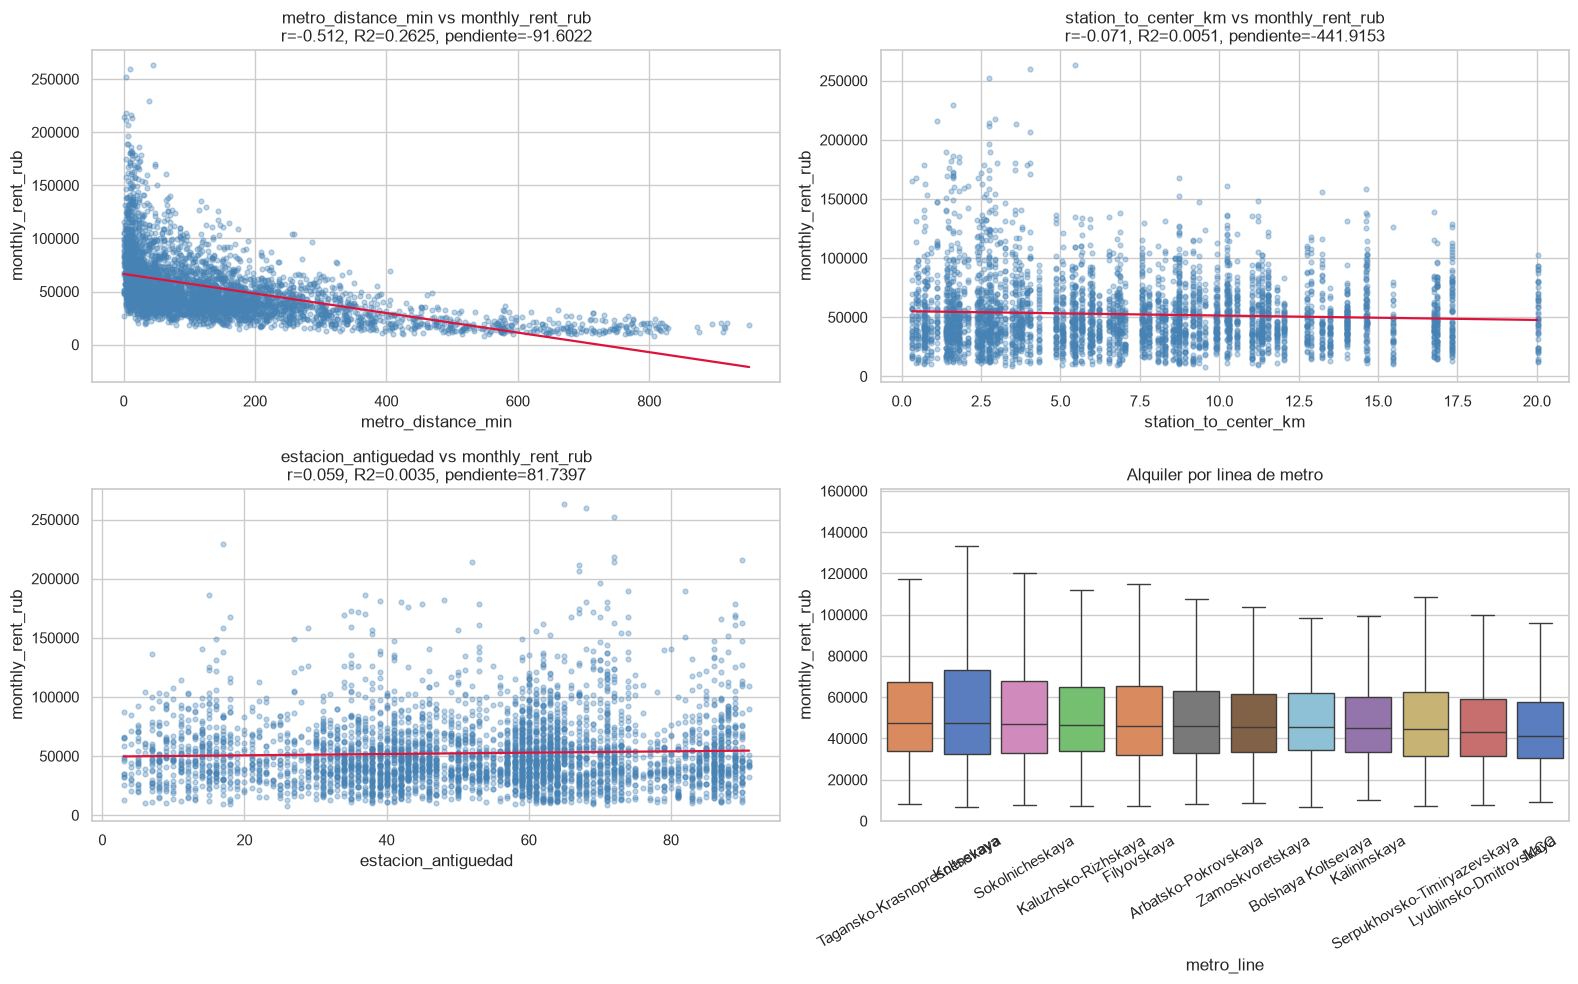

In [26]:
print(f"estaciones: {df['metro_station'].nunique()} | lineas: {df['metro_line'].nunique()}")
print("--- Alquiler por linea de metro ---")
display(df.groupby("metro_line")[TARGET]
        .agg(["count", "mean", "median", "std"]).round(0)
        .sort_values("median", ascending=False))
bins_metro = pd.cut(df["metro_distance_min"], bins=[-1, 5, 10, 20, 40, 80, 1000],
                    labels=["0-5", "5-10", "10-20", "20-40", "40-80", "80+"])
print("--- Alquiler por banda de minutos al metro ---")
display(df.groupby(bins_metro, observed=True)[TARGET]
        .agg(["count", "mean", "median", "std"]).round(0))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
scatter_reg(axes[0, 0], df, "metro_distance_min")
scatter_reg(axes[0, 1], df, "station_to_center_km")
scatter_reg(axes[1, 0], df, "estacion_antiguedad")
orden_linea = df.groupby("metro_line")[TARGET].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="metro_line", y=TARGET, ax=axes[1, 1], showfliers=False,
            order=orden_linea, hue="metro_line", legend=False, palette="muted")
axes[1, 1].set_ylim(0, df[TARGET].quantile(0.99))
axes[1, 1].tick_params(axis="x", rotation=30)
axes[1, 1].set_title("Alquiler por linea de metro")
plt.tight_layout()
plt.show()

In [27]:
TRA_NUM = ["metro_distance_min", "to_center_km", "station_to_center_km",
           "estacion_antiguedad"]
print("--- Correlaciones dentro del bloque transporte ---")
display(df[TRA_NUM + [TARGET]].corr(numeric_only=True).round(3))
print("--- VIF del bloque transporte (sin la objetivo) ---")
display(vif_tabla(df, TRA_NUM))
print("--- Significancia univariada (regresion simple contra la objetivo cruda) ---")
tra_reg = pd.DataFrame([reg_simple(df, c) for c in TRA_NUM])
display(tra_reg.sort_values("R2", ascending=False))
print(f"eta2 metro_line = {eta2(df, 'metro_line'):.3f} | "
      f"eta2 metro_station = {eta2(df, 'metro_station'):.3f}")
print("Nota: estacion_antiguedad y year_opened son la misma informacion con "
      "signo dado vuelta (correlacion -1); entra solo una al VIF.")

--- Correlaciones dentro del bloque transporte ---


,metro_distance_min,to_center_km,station_to_center_km,estacion_antiguedad,monthly_rent_rub
metro_distance_min,1.000,0.904,-0.155,0.034,-0.512
to_center_km,0.904,1.000,0.097,-0.056,-0.531
station_to_center_km,-0.155,0.097,1.000,-0.374,-0.071
estacion_antiguedad,0.034,-0.056,-0.374,1.000,0.059
monthly_rent_rub,-0.512,-0.531,-0.071,0.059,1.000


--- VIF del bloque transporte (sin la objetivo) ---


,variable,VIF
0,metro_distance_min,8.15
1,to_center_km,8.03
2,station_to_center_km,1.67
3,estacion_antiguedad,1.16


--- Significancia univariada (regresion simple contra la objetivo cruda) ---


,variable,pendiente,r,R2,p,n
1,to_center_km,-1245.6344,-0.531,0.2824,0.00e+00,20000
0,metro_distance_min,-91.6022,-0.512,0.2625,0.00e+00,20000
2,station_to_center_km,-441.9153,-0.071,0.0051,7.33e-24,20000
3,estacion_antiguedad,81.7397,0.059,0.0035,5.47e-17,20000


eta2 metro_line = 0.008 | eta2 metro_station = 0.043
Nota: estacion_antiguedad y year_opened son la misma informacion con signo dado vuelta (correlacion -1); entra solo una al VIF.


**Lectura transporte.** El alquiler cae con los minutos al metro: la mediana
pasa de 76.700 RUB en la banda 5–10 min a 37.300 RUB en la banda 80+ min, y
más de la mitad de los avisos (11.320 de 20.000) cae en esa última banda. Pero
esa señal se mezcla con la distancia al centro: `metro_distance_min` y
`to_center_km` correlacionan **r = 0,90**, con **VIF ≈ 8,2 y 8,0** — cuentan
en gran parte la misma historia.

**Variable más significativa del bloque.** En regresión simple empata el
liderazgo entre las dos mezcladas: `to_center_km` (R² = 0,28) apenas por
encima de `metro_distance_min` (R² = 0,26). Muy atrás quedan
`station_to_center_km` (R² = 0,01) y `estacion_antiguedad` (R² = 0,00). La
línea de metro explica poco por sí misma (`eta2` = 0,008; la estación,
0,043): resume zonas, no un efecto propio de la línea.


## 11. Series temporales: hacia predecir precios futuros

Como la predicción está **en el futuro**, el tiempo deja de ser un
gráfico más y pasa a ser el eje del problema: acá se describe cómo se mueve
el alquiler mes a mes, si hay estacionalidad, y cómo se reparte esa historia
entre zonas. El split temporal en sí (entrenar pasado / evaluar futuro) se
aplica en los notebooks siguientes; este EDA deja el diagnóstico.

Cuidado de fuga temporal: para predecir un mes futuro solo podrá usarse
información disponible hasta ese momento (por ejemplo, el contexto
distrito-mes del propio mes a predecir no estaría disponible completo).


meses con avisos: 64 | 2021-01 -> 2026-04


,media,mediana,mediana_m2,avisos,contexto_m2,tasa,media_movil_3m
year_month_dt,,,,,,,
2021-01-01,41638.7,35300.0,678.0,318,997.7,4.2,NaN
2021-02-01,43093.6,38900.0,700.0,297,1050.3,4.2,NaN
2021-03-01,41867.3,36250.0,691.5,312,1045.2,4.2,42199.9
2021-04-01,43174.0,38300.0,715.0,335,1074.2,8.5,42711.6
2021-05-01,45987.8,39900.0,700.0,343,1080.5,8.5,43676.4
...,...,...,...,...,...,...,...
2025-12-01,53193.0,45300.0,894.0,316,1334.8,17.0,52591.5
2026-01-01,57575.4,49500.0,926.0,305,1400.5,17.0,53552.1
2026-02-01,56584.0,48500.0,909.5,282,1332.4,17.0,55784.2


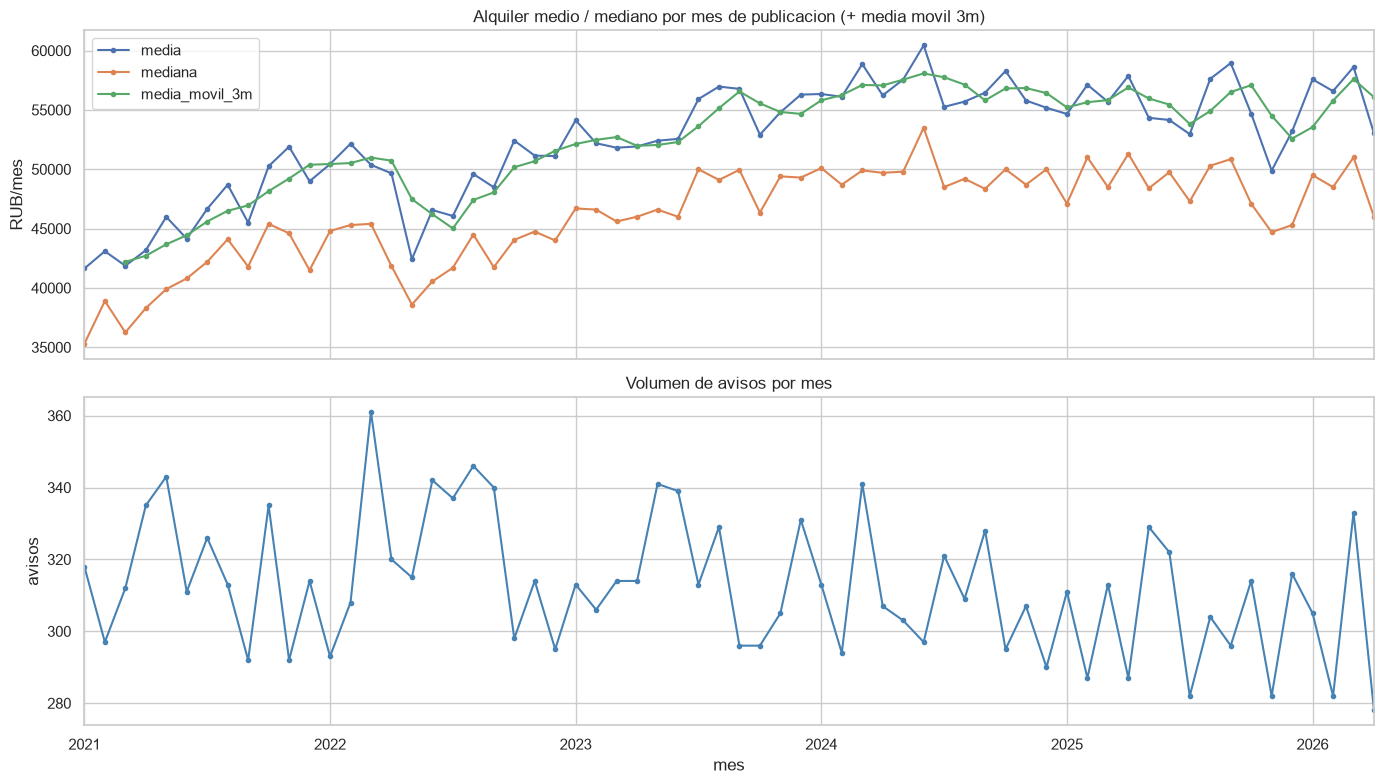

media > mediana en 64 de 64 meses (sesgo a derecha persistente en el tiempo)


In [28]:
mes = (df.groupby("year_month_dt")
       .agg(media=(TARGET, "mean"), mediana=(TARGET, "median"),
            mediana_m2=("rent_per_sqm", "median"), avisos=(TARGET, "size"),
            contexto_m2=("rental_price_per_sqm_monthly", "mean"),
            tasa=("cbr_key_rate_pct", "mean"))
       .sort_index())
mes["media_movil_3m"] = mes["media"].rolling(3).mean()
print(f"meses con avisos: {len(mes)} | {mes.index.min():%Y-%m} -> {mes.index.max():%Y-%m}")
display(mes.round(1))

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
mes[["media", "mediana", "media_movil_3m"]].plot(ax=axes[0], marker="o", markersize=3)
axes[0].set_title("Alquiler medio / mediano por mes de publicacion (+ media movil 3m)")
axes[0].set_ylabel("RUB/mes")
mes["avisos"].plot(ax=axes[1], color="steelblue", marker="o", markersize=3)
axes[1].set_title("Volumen de avisos por mes")
axes[1].set_ylabel("avisos")
axes[1].set_xlabel("mes")
plt.tight_layout()
plt.show()
print("media > mediana en", int((mes["media"] > mes["mediana"]).sum()),
      "de", len(mes), "meses (sesgo a derecha persistente en el tiempo)")

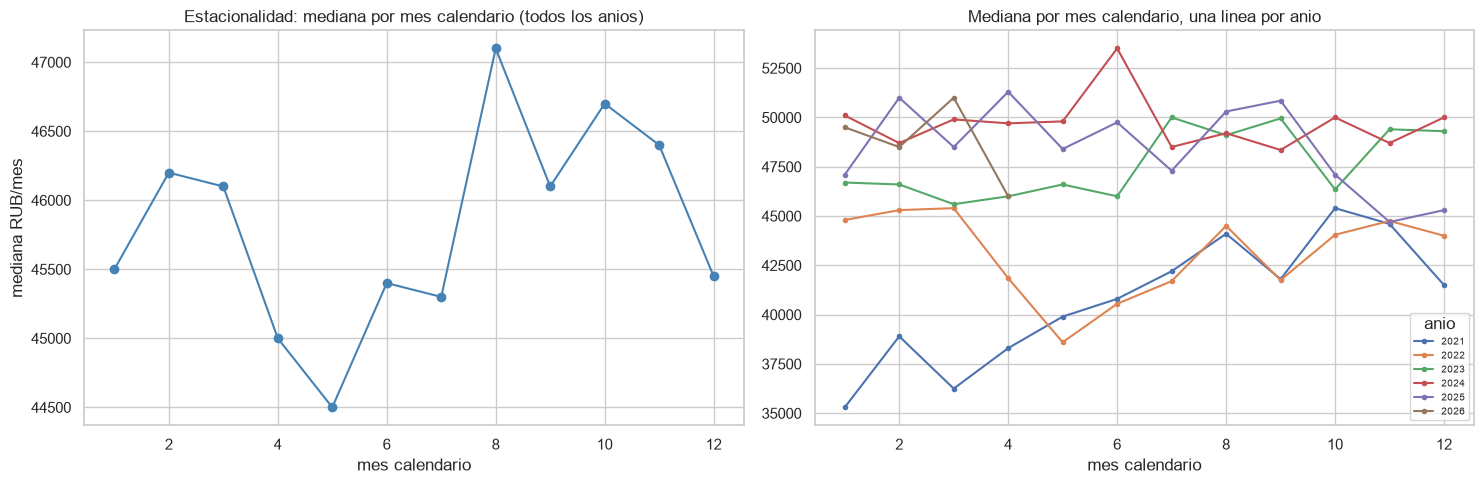

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cal = df.assign(mes_cal=df["date_posted"].dt.month).groupby("mes_cal")[TARGET].median()
cal.plot(ax=axes[0], marker="o", color="steelblue")
axes[0].set_title("Estacionalidad: mediana por mes calendario (todos los anios)")
axes[0].set_xlabel("mes calendario")
axes[0].set_ylabel("mediana RUB/mes")
por_anio = df.assign(anio=df["date_posted"].dt.year,
                     mes_cal=df["date_posted"].dt.month)
pivot = por_anio.pivot_table(index="mes_cal", columns="anio", values=TARGET,
                             aggfunc="median")
pivot.plot(ax=axes[1], marker="o", markersize=3)
axes[1].set_title("Mediana por mes calendario, una linea por anio")
axes[1].set_xlabel("mes calendario")
axes[1].legend(fontsize=7, title="anio")
plt.tight_layout()
plt.show()

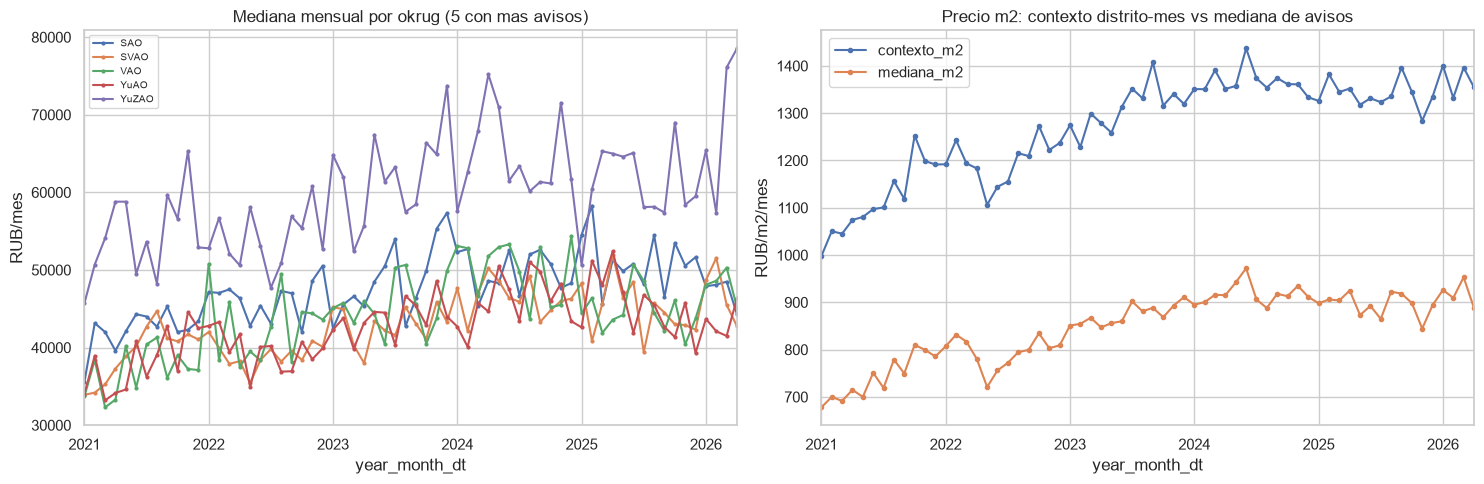

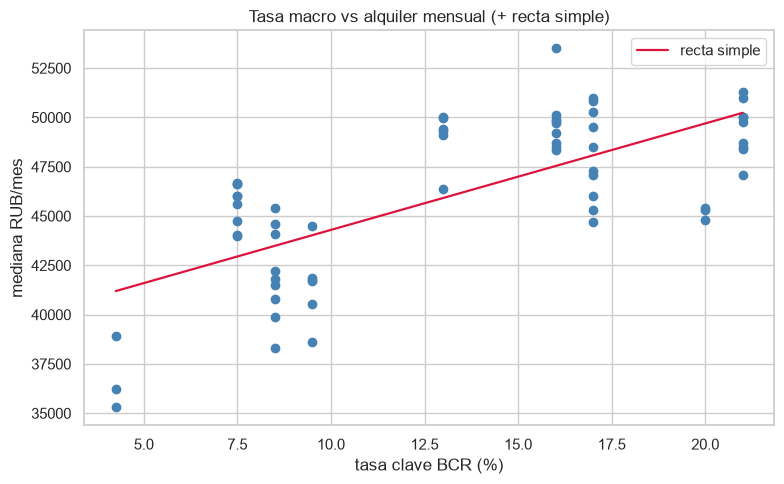

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_okrug = df["okrug"].value_counts().head(5).index
serie_okrug = (df[df["okrug"].isin(top_okrug)]
               .groupby(["year_month_dt", "okrug"])[TARGET].median().unstack())
serie_okrug.plot(ax=axes[0], marker="o", markersize=2)
axes[0].set_title("Mediana mensual por okrug (5 con mas avisos)")
axes[0].set_ylabel("RUB/mes")
axes[0].legend(fontsize=7)
mes[["contexto_m2", "mediana_m2"]].plot(ax=axes[1], marker="o", markersize=3)
axes[1].set_title("Precio m2: contexto distrito-mes vs mediana de avisos")
axes[1].set_ylabel("RUB/m2/mes")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(mes["tasa"], mes["mediana"], color="steelblue")
b, a = np.polyfit(mes["tasa"].dropna(), mes.loc[mes["tasa"].notna(), "mediana"], 1)
xs = np.linspace(mes["tasa"].min(), mes["tasa"].max(), 50)
ax.plot(xs, a + b * xs, color="crimson", lw=1.6, label="recta simple")
ax.set_xlabel("tasa clave BCR (%)")
ax.set_ylabel("mediana RUB/mes")
ax.set_title("Tasa macro vs alquiler mensual (+ recta simple)")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura temporal.** Hay 64 meses de avisos (2021-01 a 2026-04). Lo que
 domina es la **tendencia**, no la estacionalidad: la mediana anual sube de
40.400 RUB (2021) a 49.800 RUB (2024) y se mantiene en 48.400–48.600 RUB en
2025–2026, mientras que la mediana por mes calendario varía poco (de 44.500
RUB en mayo a 47.100 RUB en agosto, ratio máx/mín = 1,06). La media supera a
la mediana en **64 de 64 meses**: la cola derecha persiste todo el período.
Las series por `okrug` permiten ver si las zonas siguen esa misma tendencia
o se desacoplan en el tiempo.

Para el objetivo futuro, la consecuencia práctica es: **nada de split
aleatorio**; se entrena con meses pasados y se evalúa con meses posteriores,
y ninguna variable puede construirse con información del mes a predecir.


## 12. Outliers: diagnóstico temprano completo (no se aplica acá)

Dos miradas sobre la **objetivo cruda** y sus compañeras numéricas:

1. **Univariada:** fences de IQR, z-scores y percentiles extremos.
2. **Bivariada:** puntos extremos en los planos que importan y residuos
   grandes de rectas simples.

Después se **comparan estrategias sobre copias** (sin tratamiento, trimming,
winsorización, corrección de errores) con números y gráficos. La estrategia
que mejor se adapte queda como **recomendación**; su aplicación efectiva es
trabajo de `02_Limpieza`. La base `df` de este notebook **no se modifica**.

In [31]:
OUT_VARS = [TARGET, "total_area", "metro_distance_min", "to_center_km", "rent_per_sqm"]
filas = []
for col in OUT_VARS:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    filas.append({"variable": col, "n": len(s),
                  "fuera_IQR": int(((s < lo) | (s > hi)).sum()),
                  "pct_IQR": round(100 * ((s < lo) | (s > hi)).mean(), 2),
                  "fence_sup": round(hi, 1), "max": round(s.max(), 1),
                  "|z|>3": int((z.abs() > 3).sum()),
                  "p99": round(s.quantile(0.99), 1), "p999": round(s.quantile(0.999), 1)})
print("--- Diagnostico univariado de outliers (sobre la base enriquecida, sin tocarla) ---")
display(pd.DataFrame(filas))
print("--- Extremos de la objetivo (mayores alquileres) ---")
display(df.nlargest(10, TARGET)[["district", "okrug", "rooms", "total_area",
                                 TARGET, "rent_per_sqm", "to_center_km"]]
        .round(0))
print("--- Extremos bajos de la objetivo ---")
display(df.nsmallest(5, TARGET)[["district", "okrug", "rooms", "total_area",
                                 TARGET, "rent_per_sqm", "to_center_km"]]
        .round(0))
# Chequeos de plausibilidad (posibles errores de carga, no solo extremos)
print(f"plausibilidad: floor>total_floors={int((df['floor'] > df['total_floors']).sum())} | "
      f"total_area<=0={int((df['total_area'] <= 0).sum())} | "
      f"alquiler<=0={int((df[TARGET] <= 0).sum())} | "
      f"rent_per_sqm inconsistente (dif>5 RUB)="
      f"{int(((df['rent_per_sqm'] - df[TARGET] / df['total_area']).abs() > 5).sum())}")

--- Diagnostico univariado de outliers (sobre la base enriquecida, sin tocarla) ---


,variable,n,fuera_IQR,pct_IQR,fence_sup,max,|z|>3,p99,p999
0,monthly_rent_rub,20000,936,4.68,111800.0,300700.0,340,161102.0,229306.5
1,total_area,20000,174,0.87,89.7,104.6,47,89.2,96.2
2,metro_distance_min,20000,1416,7.08,445.5,966.0,612,776.0,909.0
3,to_center_km,20000,1905,9.52,31.5,71.1,737,66.0,68.8
4,rent_per_sqm,20000,1001,5.00,1871.5,4264.0,356,2680.0,3442.0


--- Extremos de la objetivo (mayores alquileres) ---


,district,okrug,rooms,total_area,monthly_rent_rub,rent_per_sqm,to_center_km
16744,Khamovniki,CAO,3,81.0,300700,3699,4.0
15213,Arbat,CAO,4,89.0,289300,3236,3.0
10882,Presnensky,CAO,2,70.0,282900,4048,4.0
7180,Yakimanka,CAO,4,81.0,271800,3368,2.0
17346,Yakimanka,CAO,3,73.0,270800,3709,3.0
13754,Arbat,CAO,4,89.0,263300,2965,1.0
6021,Tverskoy,CAO,4,82.0,259800,3187,3.0
6384,Khamovniki,CAO,4,76.0,259500,3392,4.0
14148,Tverskoy,CAO,3,67.0,257600,3840,4.0
7583,Presnensky,CAO,3,79.0,252000,3177,2.0


--- Extremos bajos de la objetivo ---


,district,okrug,rooms,total_area,monthly_rent_rub,rent_per_sqm,to_center_km
16566,Klyonovskoye,TAO,1,37.0,6800,183,57.0
18992,Rogovskoye,TAO,1,34.0,7000,206,67.0
15941,Rogovskoye,TAO,1,39.0,7200,184,68.0
15469,Novofyodorovskoye,TAO,1,36.0,7300,201,61.0
8902,Rogovskoye,TAO,1,36.0,7400,205,67.0


plausibilidad: floor>total_floors=0 | total_area<=0=0 | alquiler<=0=0 | rent_per_sqm inconsistente (dif>5 RUB)=0


residuos |.|>3 std de la recta area->alquiler: 357 casos


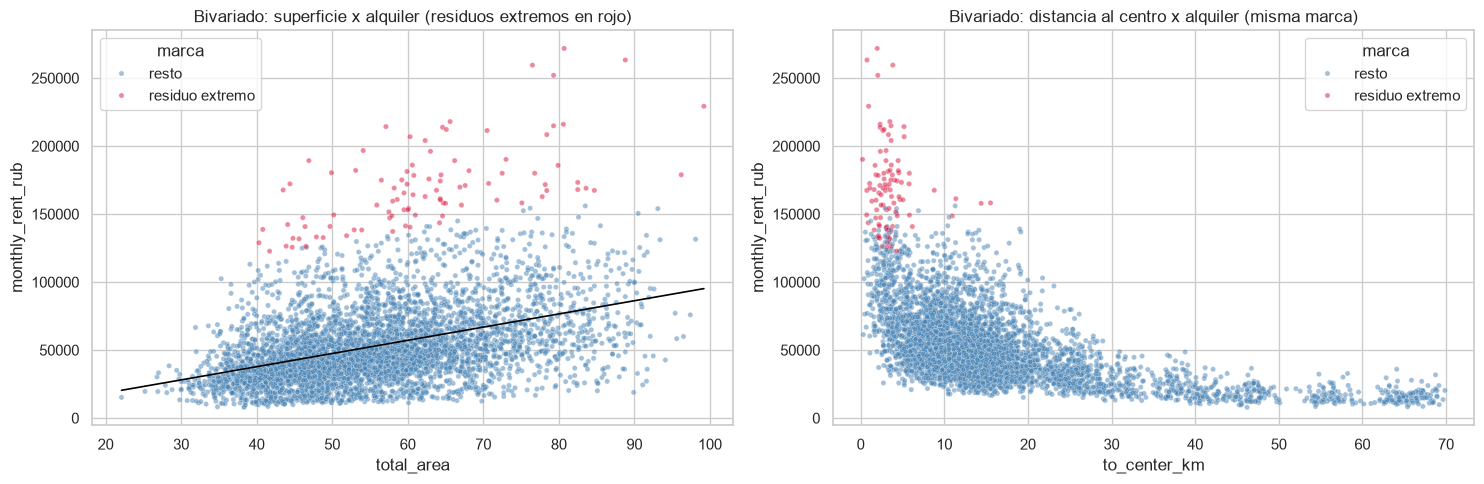

In [32]:
# Bivariado: extremos conjuntos y residuos grandes de la recta simple area->alquiler
d_biv = df[[TARGET, "total_area", "to_center_km"]].copy()
mod_area = sm.OLS(d_biv[TARGET], sm.add_constant(d_biv["total_area"].astype(float))).fit()
d_biv["resid_area"] = mod_area.resid
umbral_resid = d_biv["resid_area"].std() * 3
d_biv["marca"] = np.where(d_biv["resid_area"].abs() > umbral_resid,
                          "residuo extremo", "resto")
print(f"residuos |.|>3 std de la recta area->alquiler: "
      f"{int((d_biv['marca'] == 'residuo extremo').sum())} casos")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
s_biv = d_biv.sample(min(5000, len(d_biv)), random_state=42)
sns.scatterplot(data=s_biv, x="total_area", y=TARGET, hue="marca",
                palette={"resto": "steelblue", "residuo extremo": "crimson"},
                alpha=0.5, s=14, ax=axes[0])
b, a = np.polyfit(s_biv["total_area"], s_biv[TARGET], 1)
xs = np.linspace(s_biv["total_area"].min(), s_biv["total_area"].max(), 50)
axes[0].plot(xs, a + b * xs, color="black", lw=1.2)
axes[0].set_title("Bivariado: superficie x alquiler (residuos extremos en rojo)")
sns.scatterplot(data=s_biv, x="to_center_km", y=TARGET, hue="marca",
                palette={"resto": "steelblue", "residuo extremo": "crimson"},
                alpha=0.5, s=14, ax=axes[1])
axes[1].set_title("Bivariado: distancia al centro x alquiler (misma marca)")
plt.tight_layout()
plt.show()

--- Comparacion de estrategias (objetivo cruda; la decision final es de 02) ---


,estrategia,n,afectados,media,mediana,std,skew,kurtosis,max,R2_area
0,sin_tratamiento,20000,0,52433.0,45800.0,30003.0,1.820,5.565,300700.0,0.1688
1,trimming_IQR (descarta fuera de fences),19064,936,47999.0,44500.0,21870.0,0.669,0.004,111800.0,0.1584
2,winsor_1_99,20000,395,52148.0,45800.0,28595.0,1.397,2.361,161102.0,0.1723
3,winsor_IQR (tope en fences),20000,936,50985.0,45800.0,25249.0,0.813,0.051,111800.0,0.1812
4,correccion_errores (reglas de plausibilidad),20000,0,52433.0,45800.0,30003.0,1.820,5.565,300700.0,0.1688


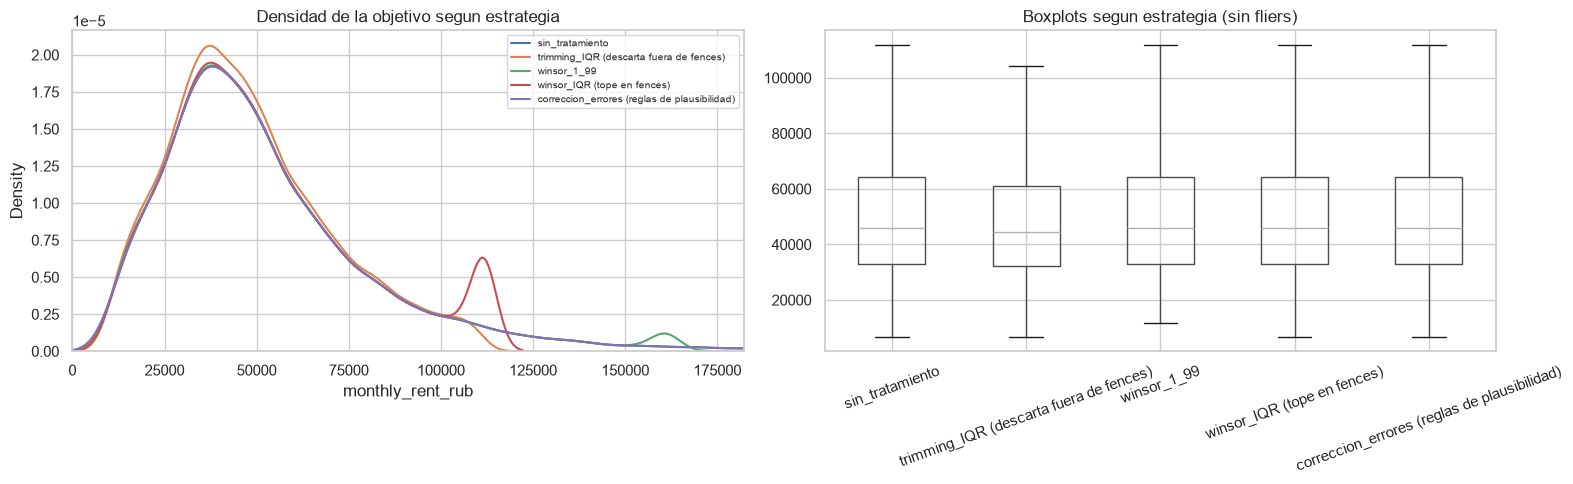

Control: la base df sigue con 20,000 filas (ninguna estrategia se aplico aca).


In [33]:
# Comparacion de estrategias SOBRE COPIAS (df queda intacta)
def winsorizar(s, lo_q, hi_q):
    return s.clip(s.quantile(lo_q), s.quantile(hi_q))


s_obj = df[TARGET].astype(float)
q1o, q3o = s_obj.quantile(0.25), s_obj.quantile(0.75)
iqr_o = q3o - q1o
lo_o, hi_o = q1o - 1.5 * iqr_o, q3o + 1.5 * iqr_o

estrategias = {
    "sin_tratamiento": s_obj,
    "trimming_IQR (descarta fuera de fences)": s_obj[(s_obj >= lo_o) & (s_obj <= hi_o)],
    "winsor_1_99": winsorizar(s_obj, 0.01, 0.99),
    "winsor_IQR (tope en fences)": s_obj.clip(lo_o, hi_o),
    # Correccion de errores: solo valores implausibles segun reglas de negocio.
    # En esta base no hay alquileres <=0 ni superficies <=0, asi que no corrige casos;
    # se incluye para que la comparacion sea completa y honesta.
    "correccion_errores (reglas de plausibilidad)": s_obj.where(s_obj > 0),
}
comp, series_comp = [], {}
for nombre, s in estrategias.items():
    s = s.dropna()
    series_comp[nombre] = s
    # Efecto sobre una recta simple comparable: alquiler ~ superficie en cada escenario
    idx = s.index.intersection(df.index)
    m_tmp = sm.OLS(s.loc[idx],
                   sm.add_constant(df.loc[idx, "total_area"].astype(float))).fit()
    comp.append({"estrategia": nombre, "n": len(s), "afectados": len(s_obj) - len(s)
                 if "trimming" in nombre else int((s != s_obj.loc[s.index]).sum()),
                 "media": round(s.mean(), 0), "mediana": round(s.median(), 0),
                 "std": round(s.std(), 0), "skew": round(float(s.skew()), 3),
                 "kurtosis": round(float(s.kurtosis()), 3),
                 "max": round(s.max(), 0),
                 "R2_area": round(float(m_tmp.rsquared), 4)})
print("--- Comparacion de estrategias (objetivo cruda; la decision final es de 02) ---")
display(pd.DataFrame(comp))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for nombre, s in series_comp.items():
    sns.kdeplot(x=s, ax=axes[0], label=nombre, clip=(0, s_obj.quantile(0.995)))
axes[0].set_xlim(0, s_obj.quantile(0.995))
axes[0].set_title("Densidad de la objetivo segun estrategia")
axes[0].legend(fontsize=7)
datos_box = pd.concat([s.rename(k) for k, s in series_comp.items()], axis=1)
datos_box.boxplot(ax=axes[1], showfliers=False)
axes[1].set_title("Boxplots segun estrategia (sin fliers)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
print(f"Control: la base df sigue con {len(df):,} filas (ninguna estrategia se aplico aca).")

**Lectura de outliers y cómo se decidirá.** Las dos miradas no coinciden en
los mismos casos, y esa es la primera conclusión:

- *Univariado:* 936 avisos (4,7%) caen sobre el fence superior de la objetivo
  (111.800 RUB) y el máximo llega a 300.700 RUB; son alquileres centrales
  reales (CAO, 70–89 m²), no errores evidentes. En predictoras, los fences
  marcan 9,5% en `to_center_km` y 7,1% en `metro_distance_min`: ahí
  \"outlier\" es en gran parte periferia, no suciedad.
- *Bivariado:* 357 casos tienen residuo |·| > 3 desvíos en la recta
  superficie→alquiler.
- *Corrección de errores:* el chequeo de plausibilidad da **cero** casos
  (sin `floor > total_floors`, sin superficies ni alquileres ≤ 0, sin
  inconsistencias en `rent_per_sqm`). En esta base, corregir errores no
  corrige nada: los extremos son mercado, no carga.

**Comparación y recomendación (a confirmar en `02_Limpieza`).** El trimming
IQR baja el skew a 0,67 y la kurtosis a 0,004, pero descarta 936 avisos
y el R² de la recta de referencia *cae* a 0,16. La winsorización 1/99
conserva `n` pero deja el skew en 1,40 y la kurtosis en 2,36. La
**winsorización en los fences de IQR** conserva los 20.000 casos, baja el
skew a **0,81** y la kurtosis de 5,57 a **0,05**, reduce el desvío de
30.003 a 25.249 RUB y da el mejor R² de referencia (0,18). La decisión final se toma en `02_Limpieza` aplicando
todas las estrategias allá y eligiendo con este mismo criterio (skew,
dispersión, kurtosis, R² y costo en casos), no con la primera
que baje el skew. Este notebook no aplica ninguna: solo diagnostica, y `df`
queda intacta.

## Cierre

- **Objetivo nuevo, target de siempre:** se predice `monthly_rent_rub`
  **a futuro** (split temporal en los próximos notebooks) y la objetivo se
  trabaja **cruda, sin normalizar ni transformar** en todo el EDA. Su QQ-plot
  y su skew confirman cola derecha pesada: es la forma del precio, no un error.
- **Joins primero:** la base enriquecida (20.000 avisos, sin perder filas)
  suma contexto distrito-mes y datos de la estación; desde ahí se analiza todo.
- **Geografía manda, pero mezclada:** hay heterogeneidad fuerte entre los 129
  distritos y los 11 `okrug` (ver `eta2` y ratio de medianas), y dentro del
  bloque las variables de contexto se explican mucho entre sí (VIF): la
  distancia al centro y el nivel distrital del mes son las señales geográficas
  centrales.
- **Superficie y ambientes comparten señal** (crecen juntas), con la
  superficie como candidata principal del bloque; `rent_per_sqm` queda fuera
  de cualquier competencia por fuga (contiene a la objetivo).
- **Transporte se confunde con centro:** minutos al metro y distancia al
  centro cuentan en parte la misma historia (correlación/VIF del bloque), y
  la tabla de `R2` simples ordena cuál domina.
- **Tiempo:** la serie mensual (2021-01 a 2026-04 en los avisos) muestra
  nivel, tendencia y comportamiento por mes calendario y por `okrug`; es la
  base para definir el corte temporal de entrenamiento/evaluación.
- **Outliers:** diagnóstico completo (univariado y bivariado) y
  estrategias comparadas sobre copias, con recomendación a confirmar en
  limpieza. Nada se aplicó a la base de este notebook.

**Próximo paso (otra sesión):** `02_Limpieza` con split temporal, aplicación
de la estrategia de outliers que resulte elegida y preparación de la base
para feature engineering y el modelo.